# 114 · embeddings and laser / frequency importance (src9 transformer)
`RUN` (default `s9-transformer-vase-1k`, ep1000): its checkpoint, the split it was trained with, and a fixed subset of that split's data
(1000 train samples + up to 40 per eval split, `split` column). `METRIC` picks the per-sample score every importance is measured with
(`METRICS` below), `REDUCER` the 3D projection of part 1 (`pca` / `tsne` / `umap`).

1. **3D embedding explorer**: model input after normalization, the latent, the decoder's penultimate layer; one dropdown recolours all three.
2. **importance** of each laser (10×10 wall grid) and each freq band (19 × ~49 Hz): token masking (key-padding), attention maps + the CLS
   question, Grad-CAM / grad×input / integrated gradients.
3. **comparison**: Spearman between the methods, summary.

Everything runs in fp32 with one batch size (`BS`): under bf16 the masks shift with the batch size (up to .09 per pixel).

## 0 · setup: run, split, data, model
`RUN` picks a src9 run; the split is the one src9 trains on (`src9/dataset.load_splits`). Data = a fixed random subset (`N_TRAIN` train samples +
up to `N_PER_EVAL` per eval split), spectra computed exactly like `dataset.process_x` (tukey, |fft| / std) and cached in `runs/_nb114_cache/<RUN>/`
(fp16 memmap, ~1.4 GB on disk, read lazily: CPU stays small). `df` has one row per sample, with a `split` column (`train` or `eval/<box>/<name>`).

The checkpoint was saved by an earlier version of `arch/transformer.py` (flat names `encoder.embed`, `encoder.lasers`, ...); the working tree groups
them into `encoder.freq_enc` / `encoder.laser_enc`. Same weights, so the keys are renamed on load. The per-box normalization stats (`cum_mean`,
`cum_std`) are buffers in the checkpoint.

In [1]:
import os, sys, json, math
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); import dataset as D9
from arch.transformer import Transformer

RUN = "s9-transformer-vase-1k"
CKPT = "latest-rank0.pt"
METRIC = "iou@0.08"
REDUCER = "tsne"           # tsne (50 PCs -> 3D t-SNE) | pca | umap
N_TRAIN, N_PER_EVAL, SEED = 1000, 40, 0
IGNORE = ["eval/cardboard/vase-laser-shifted-4"]   # splits dropped from every section (exact df split names)
RECOMPUTE = False          # True: redo the cached token-masking sweep (~7 min) and the 3D reductions
BS = 32                    # one batch size and fp32 everywhere: bf16 results shift with the batch size (up to .09 per pixel)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
args = json.loads((ROOT / f"runs/{RUN}/args.json").read_text())
assert args["model"] == "transformer" and args["window"] == "tukey", args
CACHE = ROOT / f"runs/_nb114_cache/{RUN}"; CACHE.mkdir(parents=True, exist_ok=True)
print(RUN, args["max_duration"], DEV, torch.cuda.mem_get_info() if DEV == "cuda" else "")

s9-transformer-vase-1k 1000ep cuda (9982181376, 16608133120)


In [2]:
# the split src9 trained on -> a fixed subset -> df (one row per sample)
samples, idx = D9.load_splits()
metas, dirs = list(samples.values()), list(samples)
rng = np.random.default_rng(SEED)
pick = {int(i): "train" for i in rng.choice(idx["train"], N_TRAIN, replace=False)}
for name, ids in idx.items():
    if name == "train": continue
    for i in rng.choice(ids, min(N_PER_EVAL, len(ids)), replace=False): pick.setdefault(int(i), name)
n0 = len(pick); pick = {i: s for i, s in pick.items() if s not in IGNORE}     # drawn first, then dropped: the other splits keep their samples
print(f"IGNORE {IGNORE}: dropped {n0 - len(pick)} rows")
order = sorted(pick)
boxes = sorted({m["box"] for m in metas})
objects = sorted({"+".join(sorted(metas[i]["objects"])) for i in idx["train"]}) + ["unseen"]   # as build_dataset: sets the object head size
df = pd.DataFrame([dict(i=i, split=pick[i], box=metas[i]["box"],
                        object="+".join(sorted(metas[i]["objects"])) or "empty", n_objects=metas[i]["n_objects"], speaker=metas[i]["speaker"],
                        experiment=metas[i]["experiment"], position_id=metas[i]["position_id"], sample_id=metas[i]["sample_id"], layout=metas[i]["layout"])
                   for i in order])
df["is_train"] = df.split == "train"
n_objects_all, max_k = sorted({m["n_objects"] for m in metas}), max(m["n_objects"] for m in metas)
sub = {dirs[i]: metas[i] for i in order}                  # only the picked samples' metadata; the rest (~0.8 GB of dicts) is dropped
lid = {(m["experiment"], m["without_lid_position_id"], m["speaker"]) for m in sub.values() if "without_lid_position_id" in m}
twins = {d: m for d, m in samples.items() if (m["experiment"], m["position_id"], m["speaker"]) in lid}   # process_y takes a with-lid sample's targets from these
del samples, metas, dirs; import gc; gc.collect()
print(df.split.value_counts().head(), len(df), "samples,", df.split.nunique(), "splits")

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

split
train                                       1000
eval/gastro/cube-unseen-speaker-baseline      40
eval/gastro/cube                              40
eval/gastro/vase                              40
eval/gastro/unseen-position                   40
Name: count, dtype: int64 3142 samples, 65 splits


In [3]:
# spectra X (N,L,F,C) fp16 memmap, targets Y (N,64,64), coms (N,K,2); built once per (RUN, N_TRAIN, N_PER_EVAL, SEED, IGNORE)
import hashlib
tag = f"{N_TRAIN}_{N_PER_EVAL}_{SEED}" + (f"_ign{hashlib.md5(str(sorted(IGNORE)).encode()).hexdigest()[:6]}" if IGNORE else "")
fx, fy, fc = CACHE / f"X_{tag}.npy", CACHE / f"Y_{tag}.npy", CACHE / f"coms_{tag}.npy"
if not fc.exists():
    L, F_, C = D9.load_fft(*next(iter(sub.items())), "hann").shape
    X = np.lib.format.open_memmap(fx, "w+", np.float16, (len(order), L, F_, C))
    for j, x in enumerate(D9.process_x(sub, "tukey")): X[j] = x
    X.flush(); del X
    ys = D9.process_y(sub | twins, objects, boxes, max_k, 64, 64)[:len(order)]
    np.save(fy, np.stack([y["y"] for y in ys])); np.save(fc, np.stack([y["coms"] for y in ys]))
X = np.load(fx, mmap_mode="r")                     # (N,100,1170,2) fp16, not normalized (the model normalizes)
Y = np.load(fy); COMS = np.load(fc)
BOX = torch.tensor([boxes.index(b) for b in df.box])
df["area"] = (Y > 0.5).sum((1, 2))                                     # true mask area, px of 64x64
import warnings; warnings.filterwarnings("ignore", "Mean of empty slice")
c = np.where(df.n_objects.values[:, None, None] > np.arange(COMS.shape[1])[None, :, None], COMS, np.nan)
df["com_row"], df["com_col"] = np.nanmean(c[..., 0], 1), np.nanmean(c[..., 1], 1)   # mean CoM of the objects, box fractions (row 1 = laser wall)
print(X.shape, Y.shape)

(3142, 100, 1170, 2) (3142, 64, 64)


In [4]:
# model: the working-tree arch, the checkpoint's weights (old flat names -> freq_enc / laser_enc)
sd = torch.load(ROOT / f"runs/{RUN}/checkpoints/{CKPT}", map_location="cpu", weights_only=False)["state"]["model"]
REN = {"embed": "freq_enc.embed", "band_emb": "freq_enc.freq_band_emb", "box_emb": "freq_enc.box_emb", "freqs": "freq_enc.freqs", "pool_q": "freq_enc.pool_q",
       "pool_norm": "freq_enc.pool_norm", "pool_k": "freq_enc.pool_k", "pool_o": "freq_enc.pool_o", "lasers": "laser_enc.lasers", "to_emb": "laser_enc.to_emb"}
def ren(k):
    p = k.split(".")
    return ".".join([p[0], REN[p[1]], *p[2:]]) if p[0] == "encoder" and p[1] in REN else k
sd = {ren(k): v for k, v in sd.items()}
m0 = next(iter(sub.values()))
info = dict(n_laser_rows=m0["n_rows"], n_laser_cols=m0["n_cols"], n_freqs=X.shape[2], n_channels=X.shape[3], freq_range=(float(m0["min_freq"]), float(m0["max_freq"])),
            objects=objects, n_objects=n_objects_all, boxes=boxes,
            cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].float() ** -2)
model = Transformer(info)
print(model.load_state_dict(sd, strict=True))
model = model.to(DEV).eval(); del sd
R, Cc = info["n_laser_rows"], info["n_laser_cols"]; L = R * Cc                      # 10 x 10 laser grid, laser l = (l // Cc, l % Cc)
NB = len(model.encoder.freq_band_logf); BPB = model.encoder.freq_enc.bins_per_band  # 19 freq bands of 64 bins
FREQS = np.linspace(*info["freq_range"], X.shape[2])
BAND_HZ = np.array([FREQS[min(b * BPB + BPB // 2, len(FREQS) - 1)] for b in range(NB)])   # band centres, Hz
xb = lambda ids: torch.from_numpy(X[ids].astype(np.float32)).to(DEV)               # raw (B,L,F,C) on the GPU
print(f"L={L} ({R}x{Cc}), {NB} bands of {BPB} bins ~{FREQS[BPB] - FREQS[0]:.0f} Hz")

<All keys matched successfully>
L=100 (10x10), 19 bands of 64 bins ~49 Hz


In [5]:
# per-sample metrics, (B,H,W) probabilities vs (B,H,W) truth -> (B,), nan for an empty box (as src9/utils.py iou08 / miss08)
THR = 0.08
from utils import moments
nan = lambda v, y: torch.where((y > 0.5).flatten(1).any(1), v, torch.nan)          # empty boxes don't score
def iou_at(t): return lambda p, y: nan(((p > t) & (y > 0.5)).flatten(1).sum(1) / ((p > t) | (y > 0.5)).flatten(1).sum(1).clamp_min(1), y)
def miss_at(t): return lambda p, y: nan((~((p > t) & (y > 0.5)).flatten(1).any(1)).float(), y)
METRICS = {"iou@0.08": iou_at(THR), "miss@0.08": miss_at(THR), "iou@0.5": iou_at(0.5),
           "soft_iou": lambda p, y: nan(torch.minimum(p, y).flatten(1).sum(1) / torch.maximum(p, y).flatten(1).sum(1).clamp_min(1e-6), y),
           "com_err": lambda p, y: nan((moments(p)[1] - moments(y)[1]).norm(dim=-1), y)}   # centroid distance, box fractions
HIGHER_BETTER = {"iou@0.08": True, "miss@0.08": False, "iou@0.5": True, "soft_iou": True, "com_err": False}
metric = METRICS[METRIC]

In [6]:
# baseline forward over everything (fp32; training evaluated under bf16); check against the run's own saved eval scores
@torch.no_grad()
def predict(ids, bs=BS):
    out = []
    for s in range(0, len(ids), bs):
        j = ids[s:s + bs]
        out.append(model({"fft": xb(j), "box": BOX[j].to(DEV)})["mask_pred"])
    return torch.cat(out)
P = predict(np.arange(len(df)))                                                  # (N,64,64) on the GPU
YT = torch.from_numpy(Y).to(DEV)
for k, f in METRICS.items(): df[k] = f(P, YT).cpu().numpy()
print(df.groupby(df.is_train)[list(METRICS)].mean().round(3))
import score
ev = df[~df.is_train]; one = ev.groupby("split")[METRIC].mean()
ref = score.per_sample(RUN, score.last_epoch(RUN), THR).assign(split=lambda d: "eval/" + d.box + "/" + d.split).groupby("split").iou.mean()
j = one.dropna().index.intersection(ref.index)
print(f"eval {METRIC}: sample mean {ev[METRIC].mean():.3f} over {ev[METRIC].notna().sum()} samples with an object")
print(f"{METRIC} here vs run's saved eval (same splits, subset): {one[j].mean():.3f} vs {ref[j].mean():.3f}, per-split corr {np.corrcoef(one[j], ref[j])[0, 1]:.2f}")

          iou@0.08  miss@0.08  iou@0.5  soft_iou  com_err
is_train                                                 
False        0.469      0.131    0.463     0.463    0.068
True         0.910      0.004    0.977     0.911    0.004


eval iou@0.08: sample mean 0.469 over 2142 samples with an object
iou@0.08 here vs run's saved eval (same splits, subset): 0.448 vs 0.448, per-split corr 1.00


**One eval set, one precision.** Every section uses the eval rows of `df` (up to 40 per eval split, minus `IGNORE`: 2142 samples), runs fp32, and
scores with `METRICS`, which give NaN for an empty box (as `src9/utils.py` drops them). Token masking needs a target, so it uses the eval samples
with an object; attention uses all of them; the gradient maps skip the ones with an empty *prediction*. Headline numbers differ only in how they average:
the sample mean of iou@0.08 vs the mean of split means (what `score.py` reports), both printed in setup.

## 1 · Embeddings: input, latent, penultimate
Three views of the same samples (`df`, train + eval with a `split` column), each reduced to 3D (`REDUCER` = `pca` or `tsne`), side by side.
One dropdown recolours all three panels together.

| panel | what it is | where it is grabbed (forward hook) |
|---|---|---|
| **input** | the per-box standardized spectrum, `(B, 100 lasers, 1170 bins, 2 axes)` → 234,000 | input of `model.encoder.freq_enc` |
| **latent** | the encoder output, `(B, 1024)`: what the decoder (and every aux head) reads | input of `model.decoder` |
| **penultimate** | the last decoder feature map, `(B, 32, 64, 64)` → 131,072 | input of `model.decoder.conv3` (the final 32→2 conv: mask + outline logits) |

**Where normalization happens.** `Transformer.forward()` receives the raw `batch["fft"]` (`|fft| / its std over the whole sample`, built by
`dataset.process_x`). In eval mode the train-time augs (speaker gain, laser jitter) are off, and `Encoder.forward` calls
`Encoder.normalize(x, box)` = `(x - cum_mean[box]) * cum_std[box]`: per-box, per-(laser, bin, axis) standardization with the train-set stats
stored as buffers in the checkpoint. Its output goes straight into `encoder.freq_enc`, so the hook on `freq_enc`'s input sees exactly the normalized tensor.

**No CLS token.** The laser transformer has no CLS / pooled token: its 100 laser tokens (128-d each) go through `LayerNorm → Flatten → Linear(12800, 1024)`
(`LaserEncoder.to_emb`). That 1024-d vector is the only thing the decoder sees, so it is the latent.

**Reduction.** Cached per (layer, reducer) in `runs/_nb114_cache/<RUN>/`, so switching `REDUCER` only computes the new projection (the 50 PCs are cached too). PCA is exact, through the centred `N×N` Gram matrix (features stay on the GPU in fp16, no `D×D` covariance). t-SNE / UMAP run on the top 50 PCs, fit on all points (train + eval) alike.
**speckles** = number of connected components (`scipy.ndimage.label`, 4-connectivity) of the predicted mask at `THR = 0.08` (the codebase has no other definition;
"unseen speckles" in nb113 means the laser-shifted splits, unrelated). **x / y** = the mean CoM (col / row) of the objects, box fractions (row 0 = laser wall side);
empty-box samples have no position (gray). **area** = target mask area, px of 64×64.

**Colours.** Continuous columns (area, x, y) use the p5-p95 range of that column: samples beyond it get the end colours, so a few outliers don't flatten the scale. The colour bar gives the full range, and hover gives each sample's true values.

In [7]:
import time
# forward hooks: the input of encoder.freq_enc (normalized spectrum), of the decoder (latent), of decoder.conv3 (penultimate)
# -> 50 PCs per layer (exact PCA via the centred N x N Gram matrix, features on the GPU in fp16), cached on disk
NAMES = ["input", "latent", "penultimate"]
SHAPE = {"input": (L, X.shape[2], X.shape[3]), "latent": (model.decoder.project.in_features,), "penultimate": (model.decoder.conv3.in_channels, 64, 64)}
fpc = {k: CACHE / f"pcs_{tag}_{k}.npz" for k in NAMES}

@torch.no_grad()
def pca(Z, k=50):
    G = torch.zeros(len(Z), len(Z), device=Z.device, dtype=torch.float64)
    for s in range(0, Z.shape[1], 8192):
        z = Z[:, s:s + 8192].float(); z -= z.mean(0); G += (z @ z.T).double()
    w, v = torch.linalg.eigh(G.cpu())                                         # (N,N) is small; CPU eigh
    w, v = w.flip(0).clamp_min(0), v.flip(1)
    return (v[:, :k] * w[:k].sqrt()).float().numpy(), (w / w.sum()).numpy()

if RECOMPUTE or not all(f.exists() for f in fpc.values()):
    feats = {k: [] for k in NAMES}
    grab = lambda k: (lambda mod, inp, out: feats[k].append(inp[0].flatten(1).half()))
    hooks = [model.encoder.freq_enc.register_forward_hook(grab("input")), model.decoder.register_forward_hook(grab("latent")),
             model.decoder.conv3.register_forward_hook(grab("penultimate"))]
    P2 = predict(np.arange(len(df)))
    for h in hooks: h.remove()
    print(f"hooked forward vs setup forward: max |Δp| {(P2 - P).abs().max():.1e} (fp32, same batch size)")
    for k in NAMES:
        Z = torch.cat(feats.pop(k))
        if k == "input": print(f"normalized input on the train subset: mean {Z[torch.from_numpy(df.is_train.values)].float().mean():.3f}, std {Z[torch.from_numpy(df.is_train.values)].float().std():.3f} (per-box train stats -> ~0 / ~1)")
        s, r = pca(Z); np.savez(fpc[k], pcs=s, evr=r); del Z
    del P2; torch.cuda.empty_cache()
PCS = {k: np.load(fpc[k])["pcs"] for k in NAMES}; EVR = {k: np.load(fpc[k])["evr"] for k in NAMES}

def reduce(k, how):                                                            # (N,3) coords of layer k, cached per reducer
    f = CACHE / f"red_{tag}_{k}_{how}.npy"
    if f.exists() and not RECOMPUTE: return np.load(f)
    s, t0 = PCS[k], time.time()
    if how == "pca": e = s[:, :3]
    elif how == "tsne": from sklearn.manifold import TSNE; e = TSNE(3, init="pca", perplexity=30, random_state=0).fit_transform(s)
    else: import umap; e = umap.UMAP(n_components=3, random_state=0).fit_transform(s)
    print(f"{how} {k}: {time.time() - t0:.0f} s"); np.save(f, e); return e
EMB = {k: reduce(k, REDUCER) for k in NAMES}
for k in NAMES: print(f"{k:12s} {SHAPE[k]} PC1-3 explain {EVR[k][:3].round(3)} (sum {EVR[k][:3].sum():.2f}), 50 PCs {EVR[k][:50].sum():.2f}")

hooked forward vs setup forward: max |Δp| 2.9e-04 (fp32, same batch size)
normalized input on the train subset: mean -0.004, std 0.994 (per-box train stats -> ~0 / ~1)


/tmp/ipykernel_168872/2651672634.py:27: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  if k == "input": print(f"normalized input on the train subset: mean {Z[torch.from_numpy(df.is_train.values)].float().mean():.3f}, std {Z[torch.from_numpy(df.is_train.values)].float().std():.3f} (per-box train stats -> ~0 / ~1)")


tsne input: 3 s


tsne latent: 4 s


tsne penultimate: 4 s
input        (100, 1170, 2) PC1-3 explain [0.132 0.088 0.06 ] (sum 0.28), 50 PCs 0.72
latent       (1024,) PC1-3 explain [0.094 0.054 0.048] (sum 0.20), 50 PCs 0.79
penultimate  (32, 64, 64) PC1-3 explain [0.067 0.051 0.036] (sum 0.15), 50 PCs 0.76


In [8]:
# colour columns: speckles from the setup predictions P, position from the target CoMs
from scipy import ndimage
df["speckles"] = [ndimage.label(p > THR)[1] for p in P.cpu().numpy()]   # 4-connectivity
df["x"], df["y"] = df.com_col, df.com_row
df["train/eval"] = np.where(df.is_train, "train", "eval")
print(df.speckles.value_counts().sort_index().to_dict())
print(df.groupby("is_train").speckles.mean().round(2).to_dict())

{0: 90, 1: 2707, 2: 334, 3: 11}
{False: 1.09, True: 1.08}


In [9]:
import plotly.graph_objects as go
from plotly.colors import sample_colorscale
from plotly.subplots import make_subplots

CAT8 = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]   # fixed order; a 9th level folds into "other"
GRAY = "#a3a29b"
SEQ = [[0, "#cde2fb"], [0.5, "#3987e5"], [1, "#0d366b"]]                                            # one hue, light -> dark
COLOR_BY = ["object", "n_objects", "speaker", "area", "x", "y", "box", "speckles", "train/eval"]
CONT = {"area", "x", "y"}

def colors(col):
    """-> (N,) hex per sample, legend [(label, hex)], (vmin, vmax) or None"""
    if col in CONT:
        v = df[col].astype(float).values; lo, hi = np.nanpercentile(v, [5, 95])   # colour range p5-p95: outliers get the end colours
        c = np.array([GRAY] * len(v), dtype=object); ok = ~np.isnan(v)
        c[ok] = sample_colorscale(SEQ, list(np.clip((v[ok] - lo) / (hi - lo), 0, 1)))
        return c, ([("n/a (empty box)", GRAY)] if (~ok).any() else []), (lo, hi, np.nanmin(v), np.nanmax(v))
    lab = df[col].clip(upper=6).astype(str).replace("6", "6+") if col == "speckles" else df[col].astype(str)
    lv = list(lab.value_counts().index) if col == "object" else sorted(lab.unique(), key=lambda s: (s.rstrip("+").isdigit() and float(s.rstrip("+")), s))
    if len(lv) > 8: lab = lab.where(lab.isin(lv[:7]), "other"); lv = lv[:7] + ["other"]
    cmap = {l: (GRAY if l == "other" else CAT8[i]) for i, l in enumerate(lv)}
    return lab.map(cmap).values, [(f"{l} ({(lab == l).sum()})", cmap[l]) for l in lv], None

NAMES = ["input", "latent", "penultimate"]
ax = lambda k: f"{'PC' if REDUCER == 'pca' else 'tSNE'}"
titles = [f"<b>{k}</b> {SHAPE[k]} · " + (f"PC1-3 {100 * EVR[k][:3].sum():.0f}% var" if REDUCER == "pca" else f"{REDUCER} of 50 PCs") for k in NAMES]
fig = make_subplots(1, 3, specs=[[{"type": "scene"}] * 3], subplot_titles=titles, horizontal_spacing=0.01)
hover = [f"{r.sample_id} · {r.experiment[:10]}<br>{r.object} (n={r.n_objects}) · spk {r.speaker}<br>pos {r.position_id} (row {r.com_row:.2f}, col {r.com_col:.2f})"
         f"<br>{r.split} · area {r.area} px · speckles {r.speckles}" for r in df.itertuples()]   # true values (colours clip at p5 / p95)
C = {col: colors(col) for col in COLOR_BY}
for i, k in enumerate(NAMES):                                                      # traces 0-2: the data, recoloured by the dropdown
    e = EMB[k]
    fig.add_trace(go.Scatter3d(x=e[:, 0], y=e[:, 1], z=e[:, 2], mode="markers", marker=dict(size=2.5, color=C[COLOR_BY[0]][0], opacity=0.85, line_width=0),
                               hovertext=hover, hovertemplate="%{hovertext}<extra></extra>", showlegend=False), 1, i + 1)
owner = []                                                                         # legend-only traces (and one colourbar per continuous column)
for col in COLOR_BY:
    c, leg, rng_ = C[col]
    for name, h in leg:
        fig.add_trace(go.Scatter3d(x=[None], y=[None], z=[None], mode="markers", marker=dict(size=8, color=h), name=name, visible=col == COLOR_BY[0]), 1, 1); owner.append(col)
    if rng_:
        fig.add_trace(go.Scatter3d(x=[None], y=[None], z=[None], mode="markers", showlegend=False, visible=col == COLOR_BY[0],
                                   marker=dict(color=list(rng_[:2]), cmin=rng_[0], cmax=rng_[1], colorscale=SEQ, showscale=True,
                                               colorbar=dict(title=f"{col}<br>p5-p95<br>(all {rng_[2]:.2f}-{rng_[3]:.2f})", len=0.6, thickness=12, x=1.0))), 1, 1); owner.append(col)
leg_color = [t.marker.color for t in fig.data[3:]]
buttons = [dict(label=col, method="update", args=[{"marker.color": [C[col][0]] * 3 + leg_color, "visible": [True] * 3 + [o == col for o in owner]},
                                                  {"legend.title.text": col}]) for col in COLOR_BY]
for i in range(3):
    fig.layout[f"scene{i + 1 if i else ''}"].update(xaxis_title=f"{ax(0)}1", yaxis_title=f"{ax(0)}2", zaxis_title=f"{ax(0)}3", aspectmode="cube")
fig.update_layout(width=2000, height=720, margin=dict(l=10, r=10, t=90, b=10), legend=dict(title=COLOR_BY[0], itemsizing="constant", x=1.0, y=0.98),
                  updatemenus=[dict(buttons=buttons, direction="down", x=0.0, y=1.13, xanchor="left", showactive=True)],
                  title=dict(text=f"{RUN} · {len(df)} samples ({df.is_train.sum()} train) · {REDUCER} · colour by:", x=0.08, y=0.985))
out = ROOT / f"notebooks/out/114_embeddings_{RUN}_{REDUCER}.html"; out.parent.mkdir(exist_ok=True)
fig.write_html(out, include_plotlyjs="cdn"); print(out, f"{out.stat().st_size / 1e6:.1f} MB")
fig.show()

/home/ethantu/workspace/good-vibrations/notebooks/out/114_embeddings_s9-transformer-vase-1k_tsne.html 3.1 MB


In [10]:
# what each panel is organized by, in its 3D coords. categorical: share of the 10 nearest neighbours with the same label (chance = sum p^2);
# continuous: R^2 of a linear fit from the 3 coords (rows with a value only)
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LinearRegression
rows = {}
for k in NAMES:
    e = EMB[k]; nn = NearestNeighbors(n_neighbors=11).fit(e).kneighbors(e, return_distance=False)[:, 1:]
    r = {}
    for col in COLOR_BY:
        v = df[col]
        if col in CONT: ok = v.notna().values; r[col] = LinearRegression().fit(e[ok], v[ok]).score(e[ok], v[ok])
        else: lab = np.array(v.astype(str).tolist()); r[col] = (lab[nn] == lab[:, None]).mean()
    rows[k] = r
chance = pd.Series({col: (df[col].astype(str).value_counts(normalize=True) ** 2).sum() for col in COLOR_BY if col not in CONT})
print(pd.DataFrame(rows).assign(chance=chance).round(2))

            input  latent  penultimate  chance
object       0.43    0.45         0.44    0.13
n_objects    0.89    0.95         0.93    0.81
speaker      0.99    0.75         0.24    0.24
area         0.00    0.00         0.00     NaN
x            0.00    0.55         0.69     NaN
y            0.00    0.01         0.74     NaN
box          1.00    1.00         0.68    0.36
speckles     0.82    0.88         0.89    0.75
train/eval   0.64    0.65         0.68    0.57


### embeddings: notes (written from the PCA view; the t-SNE agreement table above is the default now)
- **input** (per-box standardized, mean -0.004 / std 0.99 on train): PC1-3 hold 37% of the variance and are organized by **speaker** (10-NN agreement .91, chance .24) and **box** (.93).
  No position at all (R² of x / y / area from PC1-3 = 0.00). The dominant variance in what the model sees is the speaker and the box, not the object.
- **latent** (1024-d): the top PCs turn into **position**: x (column) R² .70, y (row) .46; speaker drops to chance (.27) along PC1-3 and box to .76.
  But t-SNE (`REDUCER="tsne"`, same 50 PCs) still finds speaker (.75) and box (1.00) neighbourhoods. So the latent is not speaker-invariant. Speaker is only pushed off the top PCs.
- **penultimate** (32×64×64 decoder map): speaker is at chance in both PCA and t-SNE (.25 / .24), and box falls to .52 / .68. x stays readable (R² .63), and y is weaker in 3D (.09).
  This is the first representation that is about the scene and not the recording.
- **object** identity is weak in 3D everywhere (PCA .22-.27, t-SNE .43-.45 vs chance .13). **area** is not linearly readable from any 3 coordinates.
- **speckles** (4-connectivity, thr .08): 2745/3178 predictions are a single blob, 332 have 2, 11 have 3, and 90 are empty. Train and eval both average 1.08 blobs, which matches the
  "no speckle" memory note.
- train vs eval sit close together in every panel (10-NN agreement .60-.62 vs chance .57). Eval points are not off-manifold in these coordinates.


## 2.1 · Token masking: which laser and frequency tokens does the transformer read?

**Tokenization** (`src9/arch/transformer.py`). Two stages, so a token is either joint or per laser:
1. **freq stage**: each laser's spectrum (1170 bins × 2 axes) is cut into **19 bands of 64 bins (~49 Hz)**. One token per **(laser, band)**:
   100 × 19 = 1900 tokens per sample. Each laser's 19 band tokens attend only to each other (2 blocks). An attention pool over the bands then
   makes **one token per laser**.
2. **laser stage**: the 100 laser tokens attend to each other (2 blocks), then LayerNorm → flatten → Linear(100·128 → 1024) → conv decoder.

**Removing a token**: key-padding mask, not zeroing the input. The cells below re-run the encoder layer by layer (src9 is not edited), with a
boolean `attn_mask` in `scaled_dot_product_attention`, so no other token can attend to the removed one. Its own output also has to be cut out
of the readout, because each stage reads every token (key-padding alone keeps the token's own residual stream):
- **band** (laser l, band j): masked as a key in laser l's freq blocks **and** in the attention pool (logit −∞, so pool weight 0 and the
  other bands renormalize). After that the token adds nothing to laser l's token.
- **freq band j**: the same, in all 100 lasers at once.
- **laser l**: masked as a key in the laser blocks **and** its slot in the flatten-Linear readout set to 0 (after the LayerNorm). That is
  exactly the model with that laser's token and its readout weights deleted.
  For comparison, `key-only` keeps the slot in the readout, so the laser still gets in through its own residual stream.

Δ = METRIC(masked) − METRIC(clean), per eval sample, then averaged. With `iou@0.08`, negative = the token helped. Eval set = the
setup's eval subset (up to 40 samples per eval split, every box), samples with an object only.

In [11]:
# eval samples with an object (an empty box has no IoU); positions into ev -> rows of X / df
ev = df[~df.is_train & (df.area > 0)][["split", "box"]].rename_axis("row").reset_index()
BOXE, YE = BOX[ev.row.values], YT[ev.row.values].cpu()
xe = lambda s: xb(ev.row.values[s])                                                 # eval positions -> raw (B,L,F,C) on the GPU
BAND_LO, BAND_HI = FREQS[np.arange(NB) * BPB], FREQS[np.minimum(np.arange(1, NB + 1) * BPB, len(FREQS)) - 1]   # band edges, Hz (last band: 18 bins + padding)
HIGHER = HIGHER_BETTER[METRIC]
print(len(ev), "eval samples with an object,", ev.split.nunique(), "splits")
print("splits with no object in any sample:", sorted(set(df[~df.is_train].split) - set(ev.split)))

2142 eval samples with an object, 64 splits
splits with no object in any sample: []


## 2.1 The encoder, layer by layer, with a keep mask
`block` = `Block.forward` plus a key-padding mask. `band_tokens` / `laser_tokens` / `mask_from` = `FreqEncoder` / `LaserEncoder` / decoder split at the
token boundaries. Check: with every token kept, this reproduces `model(batch)`.

In [12]:
E, FE, LE = model.encoder, model.encoder.freq_enc, model.encoder.laser_enc
with torch.no_grad(): LASER = E.laser_emb + E.laser_pos(E.laser_fourier)          # (L,d) laser identity + 2D position, as Encoder.forward

def block(blk, x, keep):  # Block.forward + key-padding mask: x (N,T,d), keep (N,T) bool, False = no query attends to that token
    N, T, D = x.shape
    q, k, v = blk.qkv(blk.n1(x)).view(N, T, 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    x = x + blk.o(F.scaled_dot_product_attention(q, k, v, attn_mask=keep[:, None, None, :]).transpose(1, 2).reshape(N, T, D))
    return x + blk.mlp(blk.n2(x))

def band_tokens(xn, box):  # normalized (B,L,F,C) -> (B,L,NB,d) (laser, band) tokens: FreqEncoder.forward up to its blocks
    x = F.pad(xn, (0, 0, 0, NB * BPB - xn.shape[2])).view(len(xn), L, NB, -1)
    return FE.embed(x) + FE.freq_band_emb(E.freq_band_logf[:, None])[None, None] + LASER[None, :, None] + FE.box_emb(box)[:, None, None]

def laser_tokens(t, keep):  # (B,L,NB,d) + keep (B,L,NB) -> (B,L,d): freq blocks + band pool, the removed bands masked in both
    B = len(t)
    x = t.flatten(0, 1)
    for blk in FE.freqs: x = block(blk, x, keep.flatten(0, 1))
    x = x.view(B, L, NB, -1)
    k = FE.pool_k(FE.pool_norm(x)).view(B, L, NB, FE.heads, -1)
    a = (torch.einsum("blphe,he->blhp", k, FE.pool_q) / math.sqrt(k.shape[-1])).masked_fill(~keep[:, :, None], -torch.inf).softmax(-1)  # removed band: weight 0
    return FE.pool_o((x * a.mean(2)[..., None] * NB).reshape(B, L, -1)) + LASER

def mask_from(z, keep, drop_slot=True):  # (N,L,d) laser tokens + keep (N,L) -> (N,64,64) mask prob: laser blocks, readout, decoder
    for blk in LE.lasers: z = block(blk, z, keep)
    z = LE.to_emb[0](z)                                                            # the readout's LayerNorm
    if drop_slot: z = z * keep[..., None]                                          # removed laser: its slot of the flatten-Linear reads 0
    return model.decoder(LE.to_emb[2](z.flatten(1)))[:, 0].float().sigmoid()

CHUNK = 128  # decoder batch (fp32: ~1 GB of activations)
def decode(z, keep, drop_slot=True): return torch.cat([mask_from(z[s:s + CHUNK], keep[s:s + CHUNK], drop_slot) for s in range(0, len(z), CHUNK)])

KEEP = torch.ones(1, L, NB, dtype=torch.bool, device=DEV)                        # every token kept
# exactness check in fp32 (the ablations below run in fp32 too: bf16 noise flips pixels at the 0.08 threshold, and single-token Δs are small)
with torch.no_grad():
    x, bx = xe(slice(0, 64)), BOXE[:64].to(DEV)
    p = decode(laser_tokens(band_tokens(E.normalize(x, bx), bx), KEEP.expand(64, -1, -1)), KEEP[:, :, 0].expand(64, -1))
    p_ref = model(dict(fft=x, box=bx))["mask_pred"]
print(f"all tokens kept vs model(batch), fp32: max |Δp| {(p - p_ref).abs().max():.1e}")

all tokens kept vs model(batch), fp32: max |Δp| 1.3e-03


## 2.2 Every ablation, batched (fp32)
Per step of `SB` samples: the (laser, band) tokens once; the freq stage once clean (`z0`) and once per removed band (`zb`, band j gone in every laser).
Then everything left is the laser stage + decoder on stacks of laser tokens:
- **laser l**: `z0`, keep = all but l (100 per sample), and the same with the readout slot kept (**key-only**)
- **band j**: `zb[:, j]`, keep all (19 per sample)
- **(laser l, band j)**: `z0` with row l swapped for `zb[:, j, l]`, since removing band j from laser l only changes laser l's token
  (1900 per sample, the first `N_JOINT` samples of a fixed shuffle; all of them by default)

Second baseline, **occlusion**: the token stays but its input is the box's train mean (`encoder.cum_mean[box]`, so the normalized input is
exactly 0), for a laser (all its bands) or for a band (in every laser). Occlusion asks "what if this laser/band said nothing unusual", masking
asks "what if it were not there".
The sweep is cached (`runs/_nb114_cache/<RUN>/masking_<tag>_<METRIC>.npz`, per-sample Δs); `RECOMPUTE = True` redoes it.

In [13]:
import time
N, SB, N_JOINT = len(ev), 8, 10**9                                     # SB samples per GPU step; N_JOINT samples for the (laser, band) matrix
fmask = CACHE / f"masking_{tag}_{METRIC}.npz"
PERM = np.random.default_rng(SEED).permutation(N)                                  # joint matrix: the first N_JOINT of these
NOT_L = ~torch.eye(L, dtype=torch.bool, device=DEV)                               # (L,L): row l = every laser but l
NOT_B = ~torch.eye(NB, dtype=torch.bool, device=DEV)                              # (NB,NB): row j = every band but j
ALL_L, ar = torch.ones(1, L, dtype=torch.bool, device=DEV), torch.arange(L, device=DEV)
M0 = np.zeros(N)                                                                   # clean METRIC (fp32)
D_LASER, D_KEYONLY, D_OCC_LASER = np.zeros((N, L)), np.zeros((N, L)), np.zeros((N, L))   # Δ METRIC per sample: masked, key-only, occluded
D_BAND, D_OCC_BAND = np.zeros((N, NB)), np.zeros((N, NB))
D_JOINT = np.full((N, L, NB), np.nan)
t0 = time.time()
if fmask.exists() and not RECOMPUTE: N = 0                                       # cached: skip the loop
with torch.no_grad():
    for s in range(0, N, SB):
        ids = PERM[s:s + SB]; b = len(ids)
        y, bx = YE[ids].to(DEV), BOXE[ids].to(DEV)
        t = band_tokens(E.normalize(xe(ids), bx), bx)                                                  # (b,L,NB,d)
        t_occ = band_tokens(torch.zeros(b, L, X.shape[2], X.shape[3], device=DEV), bx)                  # input = the box's train mean (normalized 0)
        z0 = laser_tokens(t, KEEP.expand(b, -1, -1))                                                   # (b,L,d) clean laser tokens
        zb = torch.stack([laser_tokens(t, NOT_B[j].expand(b, L, -1)) for j in range(NB)], 1)          # (b,NB,L,d) band j removed in every laser
        zo = laser_tokens(t_occ, KEEP.expand(b, -1, -1))                                               # (b,L,d) each laser's token with its input occluded
        zob = torch.stack([laser_tokens(torch.where((torch.arange(NB, device=DEV) == j)[:, None], t_occ, t), KEEP.expand(b, -1, -1)) for j in range(NB)], 1)  # band j occluded everywhere
        m0 = metric(decode(z0, ALL_L.expand(b, -1)), y)                                                # (b,)
        M0[ids] = m0.cpu().numpy()
        def delta(z, keep, k, **kw): return (metric(decode(z, keep, **kw), y.repeat_interleave(k, 0)).view(b, k) - m0[:, None]).cpu().numpy()
        def swap(new):  # (b,L,d) -> (b*L,L,d): copy l = z0 with laser l's token replaced by new[:, l]
            z = z0[:, None].repeat(1, L, 1, 1); z[:, ar, ar] = new; return z.flatten(0, 1)
        zl = z0[:, None].expand(b, L, L, -1).flatten(0, 1)                                              # (b*L,L,d), sample-major; keep row l = all but laser l
        D_LASER[ids] = delta(zl, NOT_L.repeat(b, 1), L)
        D_KEYONLY[ids] = delta(zl, NOT_L.repeat(b, 1), L, drop_slot=False)
        D_OCC_LASER[ids] = delta(swap(zo), ALL_L.expand(b * L, -1), L)
        D_BAND[ids] = delta(zb.flatten(0, 1), ALL_L.expand(b * NB, -1), NB)
        D_OCC_BAND[ids] = delta(zob.flatten(0, 1), ALL_L.expand(b * NB, -1), NB)
        if s < N_JOINT:                                                                                 # band j removed from laser l only
            for j in range(NB): D_JOINT[ids, :, j] = delta(swap(zb[:, j]), ALL_L.expand(b * L, -1), L)
        if (s // SB) % 50 == 0: print(f"{s + b}/{N} samples, {time.time() - t0:.0f} s, GPU peak {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
if N: np.savez(fmask, M0=M0, D_LASER=D_LASER, D_KEYONLY=D_KEYONLY, D_OCC_LASER=D_OCC_LASER, D_BAND=D_BAND, D_OCC_BAND=D_OCC_BAND, D_JOINT=D_JOINT.astype(np.float32))
globals().update(np.load(fmask)); N = len(M0)
J = PERM[:N_JOINT]
print(f"{'computed' if time.time() - t0 > 5 else 'loaded'} ({time.time() - t0:.0f} s); clean {METRIC}: {M0.mean():.4f}, setup forward {df.loc[ev.row, METRIC].mean():.4f}")

8/2142 samples, 2 s, GPU peak 4.1 GB


408/2142 samples, 68 s, GPU peak 4.1 GB


808/2142 samples, 123 s, GPU peak 4.1 GB


1208/2142 samples, 175 s, GPU peak 4.1 GB


1608/2142 samples, 228 s, GPU peak 4.1 GB


2008/2142 samples, 281 s, GPU peak 4.1 GB


computed (299 s); clean iou@0.08: 0.4690, setup forward 0.4690


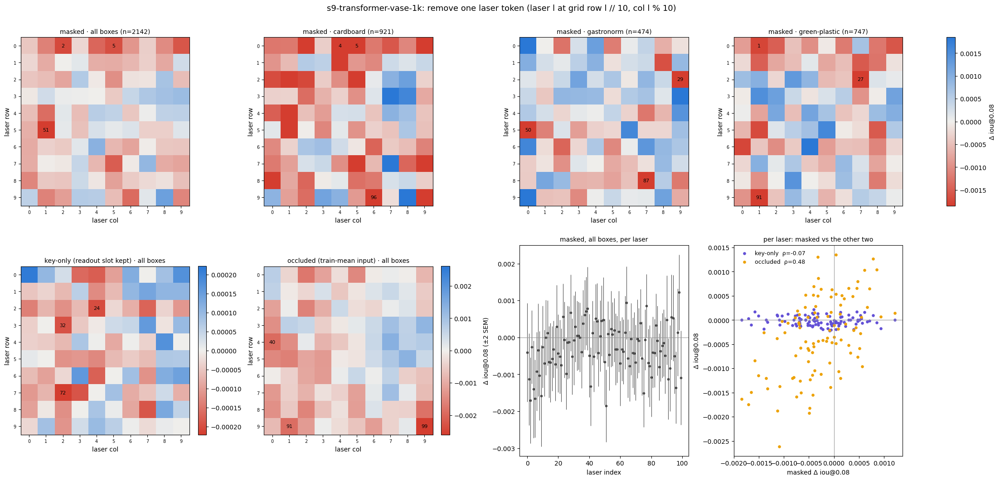

In [14]:
# red = removing it made the metric worse
DIV = LinearSegmentedColormap.from_list("div", ["#d43d2f", "#f0efec", "#2a78d6"] if HIGHER else ["#2a78d6", "#f0efec", "#d43d2f"])
BOXES = sorted(ev.box.unique())
BOX_COLOR = dict(zip(BOXES, ["#2a78d6", "#eb6834", "#1baf7a"]))                  # categorical slots 1-3
inbox = {b: (ev.box == b).values for b in BOXES}
sem = lambda a: a.std(0) / np.sqrt(len(a))                                         # standard error of the mean over samples

def grid(ax, a, title, v=None):  # (L,) -> heatmap on the 10x10 laser grid, the 3 most harmful-to-remove lasers numbered
    v = v or np.abs(a).max()
    im = ax.imshow(a.reshape(R, Cc), cmap=DIV, norm=TwoSlopeNorm(0, -v, v))
    for l in np.argsort(a if HIGHER else -a)[:3]: ax.text(l % Cc, l // Cc, l, ha="center", va="center", fontsize=8)
    ax.set_xticks(range(Cc)); ax.set_yticks(range(R)); ax.tick_params(labelsize=7); ax.set_xlabel("laser col"); ax.set_ylabel("laser row")
    ax.set_title(title, fontsize=10)
    return im

fig, axs = plt.subplots(2, 4, figsize=(22, 10.5), constrained_layout=True)
v = np.abs(D_LASER.mean(0)).max()
for ax, (name, a) in zip(axs[0], [("all boxes", D_LASER)] + [(b, D_LASER[inbox[b]]) for b in BOXES]):
    im = grid(ax, a.mean(0), f"masked · {name} (n={len(a)})", v)
fig.colorbar(im, ax=axs[0], shrink=0.8, label=f"Δ {METRIC}")
for ax, (name, a) in zip(axs[1], [("key-only (readout slot kept)", D_KEYONLY), ("occluded (train-mean input)", D_OCC_LASER)]):
    fig.colorbar(grid(ax, a.mean(0), f"{name} · all boxes"), ax=ax, shrink=0.8)
ax = axs[1, 2]
m, e = D_LASER.mean(0), sem(D_LASER)
ax.errorbar(np.arange(L), m, 2 * e, fmt="o", ms=3, color="#4a4a4a", elinewidth=0.8)
ax.axhline(0, color="#999", lw=0.8); ax.set_xlabel("laser index"); ax.set_ylabel(f"Δ {METRIC} (±2 SEM)"); ax.set_title("masked, all boxes, per laser", fontsize=10)
ax = axs[1, 3]
for name, a, c in [("key-only", D_KEYONLY, "#6250d6"), ("occluded", D_OCC_LASER, "#eda100")]:
    ax.scatter(m, a.mean(0), s=14, color=c, label=f"{name}  ρ={pd.Series(m).corr(pd.Series(a.mean(0)), method='spearman'):.2f}")
ax.axhline(0, color="#999", lw=0.8); ax.axvline(0, color="#999", lw=0.8); ax.legend(frameon=False, fontsize=9)
ax.set_xlabel(f"masked Δ {METRIC}"); ax.set_ylabel(f"Δ {METRIC}"); ax.set_title("per laser: masked vs the other two", fontsize=10)
fig.suptitle(f"{RUN}: remove one laser token (laser l at grid row l // {Cc}, col l % {Cc})", fontsize=13)
plt.show()

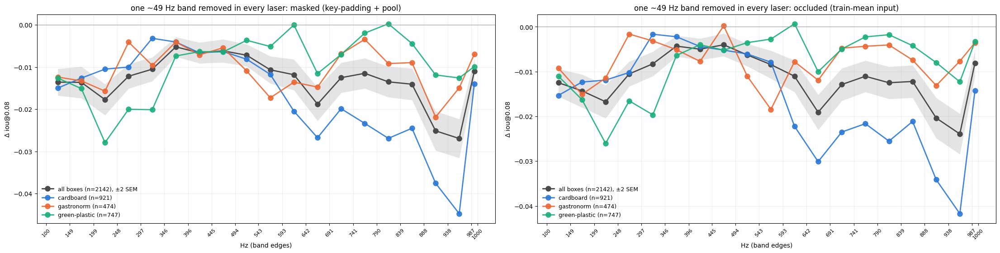

In [15]:
fc = (BAND_LO + BAND_HI) / 2                                                      # band centres, Hz
fig, axs = plt.subplots(1, 2, figsize=(22, 5.5), constrained_layout=True)
for ax, (name, D) in zip(axs, [("masked (key-padding + pool)", D_BAND), ("occluded (train-mean input)", D_OCC_BAND)]):
    m, e = D.mean(0), sem(D)
    ax.fill_between(fc, m - 2 * e, m + 2 * e, color="#4a4a4a", alpha=0.15, lw=0)
    ax.plot(fc, m, "o-", color="#4a4a4a", lw=2, ms=8, label=f"all boxes (n={len(D)}), ±2 SEM")
    for b in BOXES: ax.plot(fc, D[inbox[b]].mean(0), "o-", color=BOX_COLOR[b], lw=2, ms=8, alpha=0.9, label=f"{b} (n={inbox[b].sum()})")
    ax.axhline(0, color="#999", lw=0.8); ax.grid(alpha=0.2)
    ax.set_xticks(np.r_[BAND_LO, BAND_HI[-1]].round(), np.r_[BAND_LO, BAND_HI[-1]].round().astype(int), fontsize=8, rotation=45)
    ax.set_xlabel("Hz (band edges)"); ax.set_ylabel(f"Δ {METRIC}"); ax.set_title(f"one ~49 Hz band removed in every laser: {name}"); ax.legend(frameon=False, fontsize=9)
plt.show()

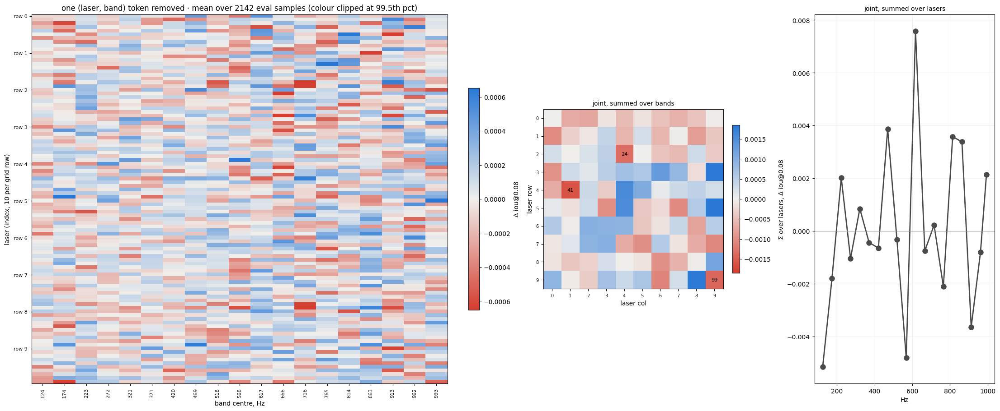

rank-1 share of the joint map 0.12;  Spearman: Σ_bands joint vs laser-masked 0.57, Σ_lasers joint vs band-masked 0.23


In [16]:
JM = D_JOINT[J].mean(0)                                                             # (L,NB) one (laser, band) token removed
v = np.percentile(np.abs(JM), 99.5)
fig, axs = plt.subplots(1, 3, figsize=(22, 9), constrained_layout=True, gridspec_kw=dict(width_ratios=[3, 1.3, 1.3]))
im = axs[0].imshow(JM, cmap=DIV, norm=TwoSlopeNorm(0, -v, v), aspect="auto")
axs[0].set_xticks(range(NB), fc.round().astype(int), rotation=90, fontsize=8); axs[0].set_yticks(range(0, L, Cc), [f"row {r}" for r in range(R)], fontsize=8)
axs[0].set_xlabel("band centre, Hz"); axs[0].set_ylabel("laser (index, 10 per grid row)")
axs[0].set_title(f"one (laser, band) token removed · mean over {len(J)} eval samples (colour clipped at 99.5th pct)")
fig.colorbar(im, ax=axs[0], shrink=0.6, label=f"Δ {METRIC}")
fig.colorbar(grid(axs[1], JM.sum(1), "joint, summed over bands"), ax=axs[1], shrink=0.4)
axs[2].plot(fc, JM.sum(0), "o-", color="#4a4a4a", lw=2, ms=8); axs[2].axhline(0, color="#999", lw=0.8)
axs[2].set_xlabel("Hz"); axs[2].set_ylabel(f"Σ over lasers, Δ {METRIC}"); axs[2].set_title("joint, summed over lasers", fontsize=10); axs[2].grid(alpha=0.2)
plt.show()

sv = np.linalg.svd(JM, compute_uv=False)
rho = lambda a, b: pd.Series(a).corr(pd.Series(b), method="spearman")
print(f"rank-1 share of the joint map {sv[0] ** 2 / (sv ** 2).sum():.2f};  Spearman: Σ_bands joint vs laser-masked {rho(JM.sum(1), D_LASER[J].mean(0)):.2f}, "
      f"Σ_lasers joint vs band-masked {rho(JM.sum(0), D_BAND[J].mean(0)):.2f}")

In [17]:
# importance = how much worse METRIC gets without the token (positive = the token helps), mean over the eval samples
sign = -1 if HIGHER else 1
IMP_MASK = imp = dict(laser=sign * D_LASER.mean(0), freq=sign * D_BAND.mean(0), joint=sign * JM,
           laser_keyonly=sign * D_KEYONLY.mean(0), laser_occ=sign * D_OCC_LASER.mean(0), freq_occ=sign * D_OCC_BAND.mean(0),
           laser_sem=sem(D_LASER), freq_sem=sem(D_BAND), **{f"laser_{b}": sign * D_LASER[inbox[b]].mean(0) for b in BOXES},
           **{f"freq_{b}": sign * D_BAND[inbox[b]].mean(0) for b in BOXES})

top_l = np.argsort(-imp["laser"])[:10]
top_b = np.argsort(-imp["freq"])[:10]
display(pd.DataFrame(dict(laser=top_l, row=top_l // Cc, col=top_l % Cc, masked=imp["laser"][top_l], sem=imp["laser_sem"][top_l],
                          key_only=imp["laser_keyonly"][top_l], occluded=imp["laser_occ"][top_l])).round(4).set_index("laser"))
display(pd.DataFrame(dict(band=top_b, hz=[f"{BAND_LO[j]:.0f}-{BAND_HI[j]:.0f}" for j in top_b], masked=imp["freq"][top_b], sem=imp["freq_sem"][top_b],
                          occluded=imp["freq_occ"][top_b], **{b: imp[f"freq_{b}"][top_b] for b in BOXES})).round(4).set_index("band"))
tj = np.argsort(-imp["joint"], axis=None)[:10]
print("top (laser, band) tokens:", ", ".join(f"L{l}·{BAND_LO[j]:.0f}-{BAND_HI[j]:.0f}Hz {imp['joint'][l, j]:.4f}" for l, j in zip(*np.unravel_index(tj, JM.shape))))

,row,col,masked,sem,key_only,occluded
laser,,,,,,
51,5,1,0.0018,0.0005,-0.0000,0.0016
2,0,2,0.0017,0.0006,-0.0000,0.0017
5,0,5,0.0017,0.0005,0.0001,0.0015
9,0,9,0.0016,0.0007,-0.0002,0.0008
75,7,5,0.0015,0.0005,-0.0001,0.0012
4,0,4,0.0014,0.0007,0.0002,0.0003
96,9,6,0.0014,0.0005,-0.0000,0.0012
41,4,1,0.0013,0.0005,0.0000,0.0014
1,0,1,0.0011,0.0006,-0.0001,0.0004


,hz,masked,sem,occluded,cardboard,gastronorm,green-plastic
band,,,,,,,
17,938-986,0.0269,0.0023,0.0239,0.0448,0.0149,0.0126
16,888-937,0.0251,0.0023,0.0204,0.0375,0.0219,0.0119
11,642-691,0.0188,0.0020,0.0191,0.0268,0.0147,0.0115
2,199-247,0.0177,0.0018,0.0167,0.0105,0.0157,0.0279
15,839-888,0.0141,0.0019,0.0122,0.0245,0.0089,0.0044
1,149-198,0.0136,0.0019,0.0143,0.0126,0.0133,0.0151
0,100-149,0.0136,0.0016,0.0125,0.0150,0.0124,0.0126
14,790-838,0.0135,0.0018,0.0125,0.0269,0.0092,-0.0003
12,691-740,0.0125,0.0018,0.0129,0.0199,0.0069,0.0070


top (laser, band) tokens: L27·642-691Hz 0.0009, L99·149-198Hz 0.0007, L5·888-937Hz 0.0007, L21·642-691Hz 0.0007, L10·839-888Hz 0.0007, L19·691-740Hz 0.0007, L79·691-740Hz 0.0006, L18·691-740Hz 0.0006, L78·691-740Hz 0.0006, L90·888-937Hz 0.0006


## 2.2 · Attention: where the lasers and the freq bands look
Every attention map of `s9-transformer-vase-1k` (ep1000) on the setup's eval subset (~2.2k samples, every eval split). The model never returns its
weights (`Block` calls `F.scaled_dot_product_attention`), so a forward hook on each `Block` grabs its input and the notebook recomputes
`softmax(q kᵀ / √d_h)` from that block's own `n1` + `qkv`; a check rebuilds each block's output from those weights.

The encoder is two transformers in a row, not one over laser×freq tokens:
1. **freq blocks** (2 layers, 4 heads): per laser, self-attention over its 19 freq bands (64 bins, ~49 Hz each). Batch = (sample, laser).
2. **band pooling**: one learned query per head (`pool_q`) attends over the 19 bands of each laser → gates the bands → `pool_o` → 1 token per laser.
3. **laser blocks** (2 layers, 4 heads): self-attention over the 100 laser tokens (10×10 wall grid, laser `l` = row `l // 10`, col `l % 10`).
4. **readout**: `LayerNorm → Flatten → Linear(100·128 → 1024)`; every laser slot has its own weights. No token is pooled.

### "The last token is the latent CLS token, right? Does that work?"
**No: there is no CLS token, first or last.** From `src9/arch/transformer.py`:
- the freq blocks see exactly the 19 band tokens of one laser (`x.flatten(0, 1)` → `(B·L, 19, d)`), nothing is appended;
- the laser blocks see exactly the 100 laser tokens, nothing is appended; `L = rows * cols` everywhere;
- the embedding is `to_emb = Sequential(LayerNorm, Flatten(1), Linear(L*d, d_model))`: all 100 tokens are concatenated and read with separate weights. The last token is just laser 99 (row 9, col 9), and the readout treats it like any other slot.

The closest thing to a latent query is in the **band pooling**: `pool_q` `(heads, d/heads)` is a learned query (no token, never attended to), softmax over each laser's 19 bands. That is a real CLS-like attention, but per laser and over freq only.

So below: **freq** "CLS" = the `pool_q` attention (exact), **laser** "CLS" = the closest analog, the flatten readout's per-laser share `‖W_l · LN(x_l)‖ / Σ_l'` (how much of the 1024-d embedding each laser slot writes), and per layer the mean attention each token *receives*. Rollout (Abnar & Zuidema 2020): `Ã = ½(mean_heads A) + ½I`, `R = Ã₂ Ã₁`, per sample, then left-multiplied by the readout share (lasers) or the pool attention (bands).

In [18]:
enc = model.encoder
EV = np.flatnonzero(~df.is_train.values)                                          # eval rows of df / X
batch = lambda j: {"fft": xb(j), "box": BOX[j].to(DEV)}
BLOCKS = {**{f"freq{i}": b for i, b in enumerate(enc.freq_enc.freqs)}, **{f"laser{i}": b for i, b in enumerate(enc.laser_enc.lasers)}}

def attn(b, x):
    """(N,T,D) block input -> (N,H,T,T) attention weights, as Block.forward computes them"""
    N, T, D = x.shape
    q, k, v = b.qkv(b.n1(x)).view(N, T, 3, b.h, -1).permute(2, 0, 3, 1, 4)
    return (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)

grab = {}
hooks = [b.register_forward_hook(lambda m, i, o, n=n: grab.__setitem__(n, (i[0], o))) for n, b in BLOCKS.items()]
hooks += [enc.freq_enc.pool_k.register_forward_hook(lambda m, i, o: grab.__setitem__("pool_k", o)),
          enc.laser_enc.to_emb[0].register_forward_hook(lambda m, i, o: grab.__setitem__("ln_out", o))]

# check: the recomputed weights rebuild each block's output
with torch.no_grad():
    model(batch(EV[:8]))
    for n, b in BLOCKS.items():
        x, out = grab[n]
        N, T, D = x.shape
        v = b.qkv(b.n1(x)).view(N, T, 3, b.h, -1).permute(2, 0, 3, 1, 4)[2]
        y = x + b.o((attn(b, x) @ v).transpose(1, 2).reshape(N, T, D)); y = y + b.mlp(b.n2(y))
        print(n, tuple(x.shape), f"max |rebuilt - out| = {(y - out).abs().max().item():.1e}")

freq0 (800, 19, 128) max |rebuilt - out| = 9.5e-07
freq1 (800, 19, 128) max |rebuilt - out| = 9.5e-07
laser0 (8, 100, 128) max |rebuilt - out| = 6.9e-07
laser1 (8, 100, 128) max |rebuilt - out| = 6.6e-07


In [19]:
# one pass over the eval subset (fp32, batches of 32): sums of every map, per-sample importances, per-sample peakedness
W = enc.laser_enc.to_emb[2].weight.view(-1, L, enc.laser_emb.shape[1])          # (1024, L, d): one weight slab per laser slot
S = {n: 0 for n in BLOCKS}                                                       # summed (H,T,T) attention per layer
imp = {k: [] for k in ("laser_read", "laser_rollout", "freq_cls", "freq_rollout", "laser_recv0", "laser_recv1", "freq_recv0", "freq_recv1")}
peak = {n: [] for n in [*BLOCKS, "pool"]}                                         # per sample: max weight of a query row, mean over rows and heads
I_f, I_l = torch.eye(NB, device=DEV), torch.eye(L, device=DEV)
with torch.no_grad():
    for s in range(0, len(EV), BS):
        j = EV[s:s + BS]; B = len(j)
        model(batch(j))
        A = {n: attn(b, grab[n][0]) for n, b in BLOCKS.items()}                  # freq: (B*L,H,19,19), laser: (B,H,100,100)
        for n, a in A.items():
            S[n] = S[n] + a.view(B, -1, *a.shape[-3:]).sum((0, 1))               # (H,T,T)
            peak[n].append(a.amax(-1).view(B, -1).mean(1))
        # band pooling: pool_q over each laser's 19 bands (as FreqEncoder.forward)
        k = grab["pool_k"].view(B, L, NB, enc.freq_enc.heads, -1)
        pa_h = (torch.einsum("blphe,he->blhp", k, enc.freq_enc.pool_q) / math.sqrt(k.shape[-1])).softmax(-1)          # (B,L,H,19)
        pa = pa_h.mean(2)                                                                                         # (B,L,19): the gate the model uses
        peak["pool"].append(pa_h.amax(-1).view(B, -1).mean(1))
        Rf = (0.5 * A["freq1"].mean(1) + 0.5 * I_f) @ (0.5 * A["freq0"].mean(1) + 0.5 * I_f)                        # (B*L,19,19)
        imp["freq_cls"].append(pa.mean(1))
        imp["freq_rollout"].append((pa.reshape(-1, 1, NB) @ Rf).view(B, L, NB).mean(1))
        # laser readout share: norm of what each slot writes into the 1024-d embedding
        w = torch.einsum("bld,eld->ble", grab["ln_out"], W).norm(dim=-1); w = w / w.sum(1, keepdim=True)               # (B,L)
        Rl = (0.5 * A["laser1"].mean(1) + 0.5 * I_l) @ (0.5 * A["laser0"].mean(1) + 0.5 * I_l)                      # (B,L,L)
        imp["laser_read"].append(w)
        imp["laser_rollout"].append((w[:, None] @ Rl)[:, 0])
        for i in (0, 1):
            imp[f"laser_recv{i}"].append(A[f"laser{i}"].mean((1, 2)))                                               # (B,L) mean attention received
            imp[f"freq_recv{i}"].append(A[f"freq{i}"].mean((1, 2)).view(B, L, NB).mean(1))                         # (B,19)
for h in hooks: h.remove()
imp = {k: torch.cat(v).cpu().numpy() for k, v in imp.items()}
peak = {k: torch.cat(v).cpu().numpy() for k, v in peak.items()}
A_mean = {n: (s / (len(EV) * (L if n.startswith("freq") else 1))).cpu().numpy() for n, s in S.items()}   # (H,T,T)
print(len(EV), "eval samples; GPU peak", round(torch.cuda.max_memory_allocated() / 2**30, 2), "GB")

2142 eval samples; GPU peak 3.8 GB


## 2a · where single lasers look (laser blocks)
Each small map = one query laser's attention row (mean over heads and eval samples), on the 10×10 wall grid; the black square marks the query.
The laser tokens already carry their whole spectrum (the freq blocks + band pooling run first), so there is no freq axis left to marginalize.
Colour scale per map, 0 to its own peak (title: weight on itself and the peak; uniform = 0.01).

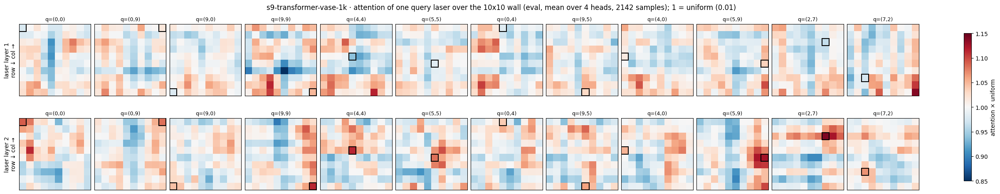

In [20]:
Q = [(0, 0), (0, 9), (9, 0), (9, 9), (4, 4), (5, 5), (0, 4), (9, 5), (4, 0), (5, 9), (2, 7), (7, 2)]   # corners, centre, edge middles, two inner
fig, axes = plt.subplots(2, len(Q), figsize=(2.0 * len(Q), 4.8), constrained_layout=True)
for r, n in enumerate(["laser0", "laser1"]):
    a = A_mean[n].mean(0) * L                                                      # (L,L) mean over heads, x uniform (1 = 1/100)
    for ax, (qr, qc) in zip(axes[r], Q):
        im = ax.imshow(a[qr * Cc + qc].reshape(R, Cc), cmap="RdBu_r", vmin=0.85, vmax=1.15)
        ax.add_patch(plt.Rectangle((qc - .5, qr - .5), 1, 1, fill=False, ec="black", lw=1.5))
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"q=({qr},{qc})", fontsize=9)
    axes[r, 0].set_ylabel(f"laser layer {r + 1}\nrow ↓ col →", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8, label="attention × uniform")
fig.suptitle(f"{RUN} · attention of one query laser over the 10x10 wall (eval, mean over 4 heads, {len(EV)} samples); 1 = uniform (0.01)")
plt.show()

In [21]:
# how peaked / how local? per sample: the largest weight in a query row (uniform = 1/T), mean over rows + heads; and for the eval-mean
# laser maps the attention-weighted grid distance (cells) vs uniform
rc = np.stack(np.divmod(np.arange(L), Cc), 1); dist = np.linalg.norm(rc[:, None] - rc[None], axis=-1)   # (L,L) cells
for n in [*BLOCKS, "pool"]:
    T = L if n.startswith("laser") else NB
    line = f"{n:7s} max weight per row: median {np.median(peak[n]):.3f}, 99th pct {np.percentile(peak[n], 99):.3f} (uniform {1 / T:.3f})"
    if n.startswith("laser"): line += f" · mean distance {(A_mean[n].mean(0) * dist).sum(-1).mean():.2f} cells (uniform {dist.mean():.2f})"
    print(line)

freq0   max weight per row: median 0.082, 99th pct 0.092 (uniform 0.053)
freq1   max weight per row: median 0.081, 99th pct 0.091 (uniform 0.053)
laser0  max weight per row: median 0.020, 99th pct 0.025 (uniform 0.010) · mean distance 5.20 cells (uniform 5.19)
laser1  max weight per row: median 0.019, 99th pct 0.025 (uniform 0.010) · mean distance 5.17 cells (uniform 5.19)
pool    max weight per row: median 0.075, 99th pct 0.084 (uniform 0.053)


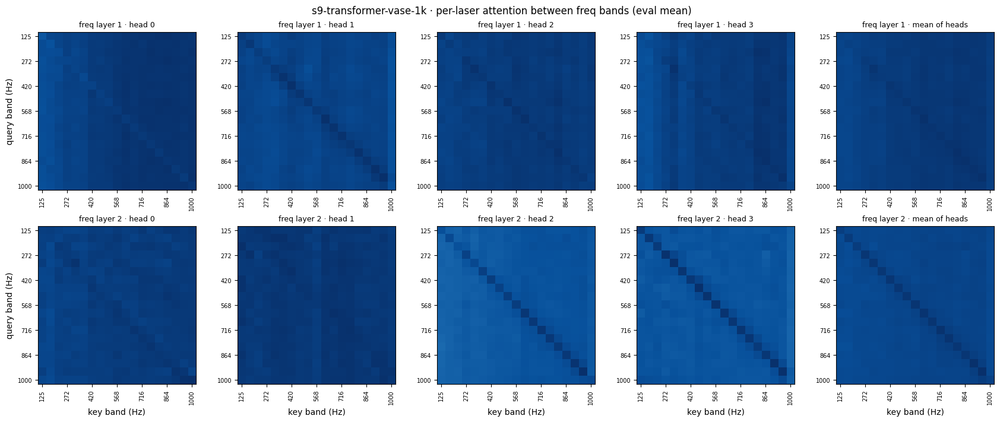

In [22]:
# the freq blocks: each laser's 19x19 band-to-band attention (mean over lasers, samples), per layer and head
fig, axes = plt.subplots(2, 5, figsize=(17, 7), constrained_layout=True)
for r, n in enumerate(["freq0", "freq1"]):
    for h in range(5):
        a = A_mean[n].mean(0) if h == 4 else A_mean[n][h]
        ax = axes[r, h]; ax.imshow(a, cmap="Blues", vmin=0)
        ax.set_title(f"freq layer {r + 1} · " + ("mean of heads" if h == 4 else f"head {h}"), fontsize=9)
        tk = np.arange(0, NB, 3); ax.set_xticks(tk, [f"{BAND_HZ[t]:.0f}" for t in tk], fontsize=7, rotation=90); ax.set_yticks(tk, [f"{BAND_HZ[t]:.0f}" for t in tk], fontsize=7)
    axes[r, 0].set_ylabel("query band (Hz)")
for ax in axes[1]: ax.set_xlabel("key band (Hz)")
fig.suptitle(f"{RUN} · per-laser attention between freq bands (eval mean)")
plt.show()

## 2b · the CLS analogs: what the embedding reads, per layer and rolled out
Top row (lasers, 10×10 wall): mean attention *received* in laser layers 1 and 2, the readout share (which slots write into the embedding), and the rollout (readout share pushed back through both laser layers with the residual identity). Bottom row (bands): mean attention received in freq layers 1 and 2, the `pool_q` attention (the one real learned-query/CLS-like softmax), and its rollout through both freq layers. Dashed = uniform.

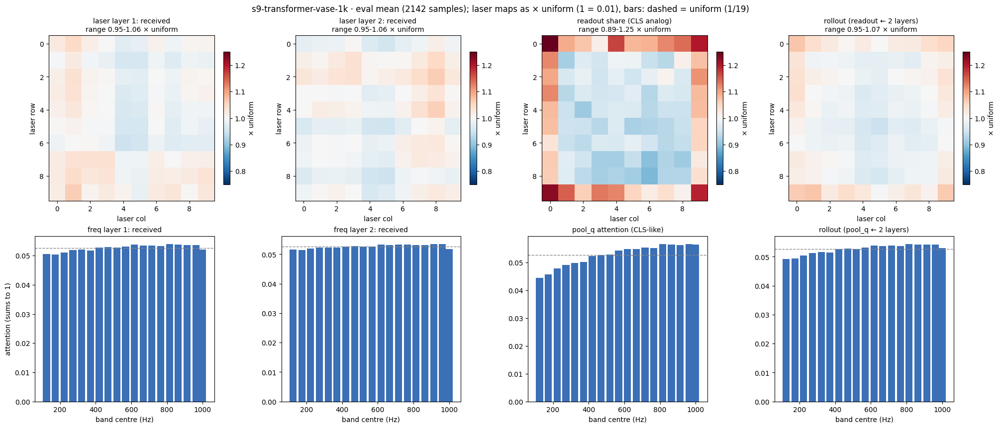

In [23]:
mean = lambda k: imp[k].mean(0)
laser = {"laser layer 1: received": mean("laser_recv0"), "laser layer 2: received": mean("laser_recv1"),
         "readout share (CLS analog)": mean("laser_read"), "rollout (readout ← 2 layers)": mean("laser_rollout")}
freq = {"freq layer 1: received": mean("freq_recv0"), "freq layer 2: received": mean("freq_recv1"),
        "pool_q attention (CLS-like)": mean("freq_cls"), "rollout (pool_q ← 2 layers)": mean("freq_rollout")}
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5), constrained_layout=True)
for ax, (t, v) in zip(axes[0], laser.items()):
    im = ax.imshow(v.reshape(R, Cc) * L, cmap="RdBu_r", vmin=0.75, vmax=1.25); fig.colorbar(im, ax=ax, shrink=0.8, label="× uniform")
    ax.set_title(f"{t}\nrange {v.min() * L:.2f}-{v.max() * L:.2f} × uniform", fontsize=10); ax.set_xlabel("laser col"); ax.set_ylabel("laser row")
for ax, (t, v) in zip(axes[1], freq.items()):
    ax.bar(BAND_HZ, v, width=0.8 * (BAND_HZ[1] - BAND_HZ[0]), color="#3B6FB6")
    ax.axhline(1 / NB, color="#888888", ls="--", lw=1)
    ax.set_title(t, fontsize=10); ax.set_xlabel("band centre (Hz)"); ax.set_ylim(0, None)
axes[1, 0].set_ylabel("attention (sums to 1)")
fig.suptitle(f"{RUN} · eval mean ({len(EV)} samples); laser maps as × uniform (1 = 0.01), bars: dashed = uniform (1/19)")
plt.show()

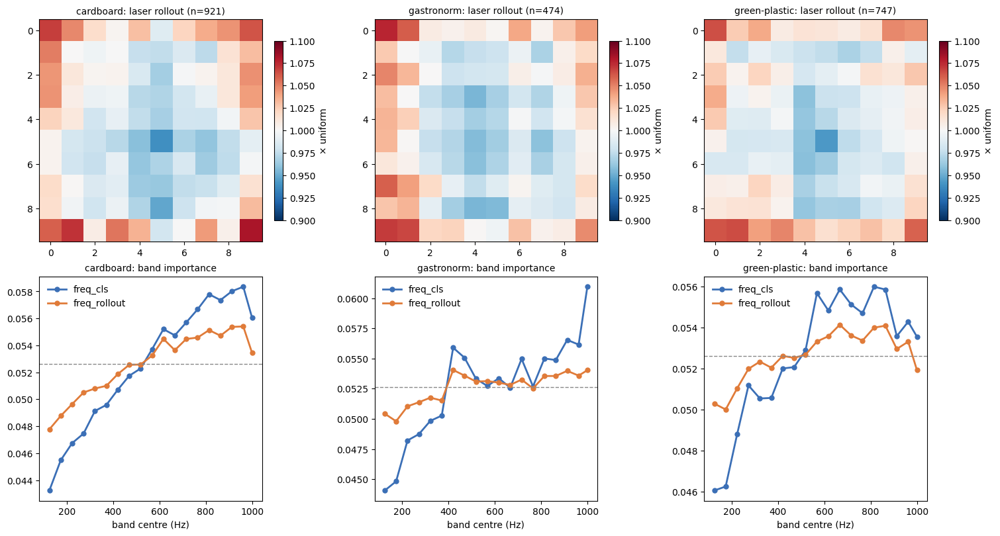

corr of laser rollout maps between boxes: [[1.0, 0.82, 0.85], [0.82, 1.0, 0.78], [0.85, 0.78, 1.0]]
laser rollout: per-sample std / std of the mean map = 1.99


In [24]:
# per box: do the boxes read the same lasers / bands?
boxes_ev = df.box.values[EV]
fig, axes = plt.subplots(2, len(boxes), figsize=(5 * len(boxes), 8), constrained_layout=True)
for c, b in enumerate(boxes):
    s = boxes_ev == b
    v = imp["laser_rollout"][s].mean(0)
    im = axes[0, c].imshow(v.reshape(R, Cc) * L, cmap="RdBu_r", vmin=0.9, vmax=1.1); fig.colorbar(im, ax=axes[0, c], shrink=0.8, label="× uniform")
    axes[0, c].set_title(f"{b}: laser rollout (n={s.sum()})", fontsize=10)
    for k, col in [("freq_cls", "#3B6FB6"), ("freq_rollout", "#E07B39")]:
        axes[1, c].plot(BAND_HZ, imp[k][s].mean(0), "o-", color=col, lw=2, ms=5, label=k)
    axes[1, c].axhline(1 / NB, color="#888888", ls="--", lw=1); axes[1, c].set_xlabel("band centre (Hz)"); axes[1, c].legend(frameon=False)
    axes[1, c].set_title(f"{b}: band importance", fontsize=10)
plt.show()
print("corr of laser rollout maps between boxes:", np.round(np.corrcoef([imp["laser_rollout"][boxes_ev == b].mean(0) for b in boxes]), 2).tolist())
print("laser rollout: per-sample std / std of the mean map =", round(float(imp["laser_rollout"].std(0).mean() / mean("laser_rollout").std()), 2))

In [25]:
IMP_ATTN = dict(laser_readout=mean("laser_read"), laser_rollout=mean("laser_rollout"), freq_pool=mean("freq_cls"), freq_rollout=mean("freq_rollout"))

### attention: findings
- **Attention is close to uniform everywhere.** Per sample, the largest weight in a query row is ~2× uniform at most (laser blocks: median 0.020 vs 0.010; freq blocks: 0.082 vs 0.053; `pool_q`: 0.075 vs 0.053). Averaged over samples it flattens further: every laser query map lies within about ±10% of 0.01, and the mean attended distance is the uniform one (5.2 cells). **The laser blocks do not route to specific lasers.** The only visible structure is in layer 2: the query and its immediate neighbours get about 1.1-1.15× uniform, a weak self/local bump. Each layer adds roughly the mean of all laser tokens (a global context vector) to every token, and the spatial information stays in the residual stream.
- **Freq blocks:** layer 1 is diffuse. Layer 2, heads 2 and 3, put mild extra weight on the band itself (the diagonal), so those heads are mostly per-band MLP-like. There is no cross-band pattern (no harmonics, no low→high routing).
- **Band pooling (`pool_q`, the only real CLS-like query):** a gentle tilt toward high frequencies, from 0.84× uniform at 125 Hz to 1.07× at ≥800 Hz. After rollout through the freq blocks it stays 0.93-1.03×. It works as a near-uniform gate, and the band selection happens in `pool_o`'s per-band weights, not in the softmax.
- **Lasers:** the readout share (each flatten slot's contribution to the embedding) is the most structured map, at 0.89-1.25× uniform. **Edge and corner lasers write more** (rows 0/9, cols 0/9) than the interior. The rollout keeps that border ring but flattens it to 0.95-1.07×. The pattern is shared by the boxes (map correlation 0.77-0.85), and per-sample variation is 2× the spatial contrast of the mean map. It is a weak, mostly sample-specific signal.
- **Does a last-token CLS work here? There isn't one.** The model reads all 100 laser slots with a flatten + Linear, which keeps laser identity. Given how uniform the laser attention is, a CLS token reading through these blocks would act close to mean pooling and lose the per-laser layout, which the flatten readout keeps. Attention maps say little about this model; use gradient or occlusion importances for attribution.

## 2.3 · Grad-CAM, grad×input, integrated gradients: which lasers × freqs drive the mask
The input as an image: 100 lasers (10×10 wall grid) × 1170 freq bins (100-1000 Hz), 2 channels summed. Three attributions on the eval subset of `00_setup`:
- **Grad-CAM** (`pytorch_grad_cam`, jacobgil): on the last freq block's tokens, one per (laser, 64-bin band) = a 100×19 "image"; `reshape_transform` turns the (B·L, 19, d) tokens into (B, d, L, 19), the input is fed as (B, C, L, F), so the lib's resize maps 100×19 → 100×1170: laser rows stay exact and only the 19 bands are interpolated along freq (no 10×10 → image stretch). The lib also min-max scales each sample, so its absolute values aren't comparable across samples; we only use per-sample shares.
- **HiResCAM** (hand-written, ~4 lines): grads × acts summed over d on the last *laser*-stage block (100 tokens → 10×10), relu, no resize; laser-only, no freq axis.
- **grad × input** and **integrated gradients** (16 steps) on the per-box *normalized* input, baseline 0 = the train mean (as nb104), |·| summed over channels.

**Target:** the predicted mask logits summed inside the predicted mask (p > 0.08): "what keeps the model painting what it paints", one scalar per sample, no class needed; samples with an empty prediction are skipped. Each sample's map is scaled to sum 1 before averaging, so every sample counts once.
`pytorch_grad_cam` is installed in `.venv` and used as is; HiResCAM, grad×input and IG are a few lines of torch.

In [26]:
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM

class Wrap(torch.nn.Module):   # the lib wants module(tensor) -> per-sample outputs; input (B,C,L,F) so the cam is resized to (L,F)
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): return s.m({"fft": x.permute(0, 2, 3, 1), "box": s.box})["mask_logits"]
wrap = Wrap(model).eval()
cam = GradCAM(wrap, target_layers=[model.encoder.freq_enc.freqs[-1]], reshape_transform=lambda a: a.view(-1, L, *a.shape[1:]).permute(0, 3, 1, 2))  # (B*L,19,d) -> (B,d,L,19)

enc = model.encoder
def head(xn, box):   # normalized (B,L,F,C) -> (B,64,64) mask logits, the encoder without its normalize
    laser = enc.laser_emb + enc.laser_pos(enc.laser_fourier)
    return model.decoder(enc.laser_enc(enc.freq_enc(xn, box, enc.freq_band_logf, laser), laser))[:, 0]
def grads(xn, box, M): xn = xn.detach().requires_grad_(); return torch.autograd.grad((head(xn, box) * M).sum(), xn)[0]
STEPS = 16

ACT = {}
enc.laser_enc.lasers[-1].register_forward_hook(lambda m, i, o: ACT.update(a=o))   # laser-stage tokens (B,100,d)
def hirescam(x, box, M):   # HiResCAM by hand: sum_d grad*act per laser token, relu, no resize -> (B,100)
    lo = model({"fft": x, "box": box})["mask_logits"]
    a = ACT["a"]; return (torch.autograd.grad((lo * M).sum(), a)[0] * a).sum(-1).relu()

In [27]:
# fp32 on the GPU, batches of 16; every map (B,L,F) scaled to sum 1 per sample
METHODS = ["gradcam", "gxi", "ig"]
S = {k: np.zeros((L, len(FREQS))) for k in METHODS}
HR = np.zeros(L); EX = {}; n_ok = 0
norm = lambda a: a / a.sum((1, 2), keepdims=True).clip(1e-12)
for s in range(0, len(EV), 16):           # 16: IG holds 16 steps of activations
    j = EV[s:s + 16]
    x, box = xb(j), BOX[j].to(DEV)
    with torch.no_grad(): M = (model({"fft": x, "box": box})["mask_logits"].sigmoid() > THR).float()
    ok = M.flatten(1).any(1).cpu().numpy()
    wrap.box = box
    gc = cam(x.permute(0, 3, 1, 2), targets=[lambda o, m=m: (o * m).sum() for m in M])              # (B,L,F) in [0,1]
    xn = enc.normalize(x, box)
    gxi = (grads(xn, box, M) * xn).abs().sum(-1)
    ig = (sum(grads(a * xn, box, M) for a in (torch.arange(STEPS, device=DEV) + 0.5) / STEPS) / STEPS * xn).abs().sum(-1)
    hr = hirescam(x, box, M).detach().cpu().numpy(); HR += (hr / hr.sum(1, keepdims=True).clip(1e-12))[ok].sum(0)
    maps = dict(gradcam=norm(gc), gxi=norm(gxi.detach().cpu().numpy()), ig=norm(ig.detach().cpu().numpy()))
    for k, a in maps.items():
        S[k] += a[ok].sum(0)
    for b, i in enumerate(j):
        if ok[b] and df.split.iloc[i] not in EX and len(EX) < 64: EX[df.split.iloc[i]] = (i, {k: a[b] for k, a in maps.items()}, M[b].cpu().numpy())
    n_ok += ok.sum()
MAP = {k: v / n_ok for k, v in S.items()}
LM = ["gradcam", "hirescam", "gxi", "ig"]                       # laser-level methods
LAS = {k: MAP[k].sum(1) for k in METHODS} | {"hirescam": HR / n_ok}
print(f"{n_ok}/{len(EV)} eval samples with a non-empty predicted mask")

2066/2142 eval samples with a non-empty predicted mask


### Average laser × freq map (eval set)
Rows = laser index (row·10 + col), columns = freq. Each method's colour scale is its own (99th pct).

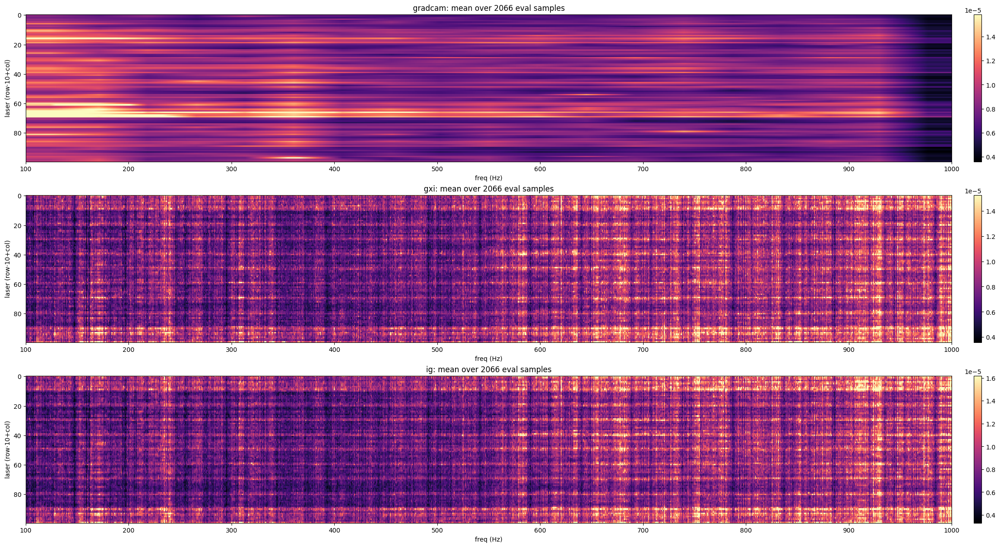

In [28]:
fig, axs = plt.subplots(len(METHODS), 1, figsize=(22, 4 * len(METHODS)), constrained_layout=True)
for ax, k in zip(axs, METHODS):
    im = ax.imshow(MAP[k], aspect="auto", cmap="magma", vmax=np.percentile(MAP[k], 99), extent=[FREQS[0], FREQS[-1], L - 0.5, -0.5], interpolation="nearest")
    ax.set(title=f"{k}: mean over {n_ok} eval samples", xlabel="freq (Hz)", ylabel="laser (row·10+col)"); fig.colorbar(im, ax=ax, pad=0.005)
plt.show()

### Laser marginal on the 2D laser grid
Sum over freq, shown on the 10×10 grid (laser l at row l // 10, col l % 10, the dataset's convention; row 0 is the `grid_coords` top row). Dashed line = uniform (1/100).

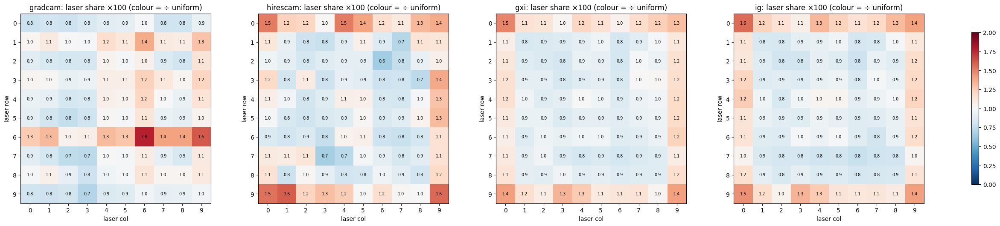

In [29]:
fig, axs = plt.subplots(1, len(LM), figsize=(6 * len(LM), 5.2), constrained_layout=True)
for ax, k in zip(axs, LM):
    g = LAS[k].reshape(R, Cc)
    im = ax.imshow(g / g.mean(), cmap="RdBu_r", vmin=0, vmax=2)
    for r in range(R):
        for c in range(Cc): ax.text(c, r, f"{g[r, c] * 100:.1f}", ha="center", va="center", fontsize=7)
    ax.set(title=f"{k}: laser share ×100 (colour = ÷ uniform)", xlabel="laser col", ylabel="laser row", xticks=range(Cc), yticks=range(R))
fig.colorbar(im, ax=axs, shrink=0.8); plt.show()

### Freq marginal
Sum over lasers, per bin (thin) and per 64-bin model band (steps). Grad-CAM is band-resolution by construction.

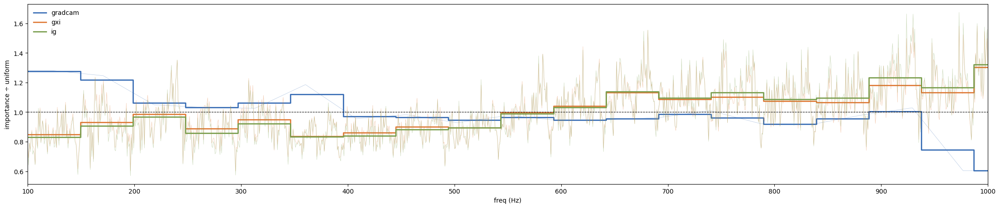

In [30]:
fig, ax = plt.subplots(figsize=(22, 4.5), constrained_layout=True)
band = lambda f: np.add.reduceat(f, np.arange(0, len(f), BPB)) / np.diff(np.r_[np.arange(0, len(f), BPB), len(f)])
for k, col in zip(METHODS, ["#3B6FB6", "#E07B39", "#7A9E4E"]):
    f = MAP[k].sum(0) * len(FREQS)                      # 1 = uniform
    ax.plot(FREQS, f, color=col, lw=0.5, alpha=0.4)
    ax.step(np.r_[FREQS[::BPB], FREQS[-1]], np.r_[band(f), band(f)[-1]], where="post", color=col, lw=2, label=k)
ax.axhline(1, color="k", ls="--", lw=0.8); ax.set(xlabel="freq (Hz)", ylabel="importance ÷ uniform", xlim=(FREQS[0], FREQS[-1])); ax.legend(frameon=False)
plt.show()

In [31]:
# top lasers / bands per method
rows = []
for k in LM:
    lz, fz = LAS[k], band(MAP[k].sum(0) * len(FREQS)) if k in MAP else np.zeros(0)
    tl, tb = np.argsort(-lz)[:8], np.argsort(-fz)[:5]
    rows.append(dict(method=k, top_lasers=", ".join(f"({l // Cc},{l % Cc}) {lz[l] * 100:.1f}%" for l in tl),
                     top_bands=", ".join(f"{FREQS[b * BPB]:.0f}-{FREQS[min(b * BPB + BPB, len(FREQS)) - 1]:.0f}Hz ×{fz[b]:.2f}" for b in tb)))
pd.set_option("display.max_colwidth", 200); display(pd.DataFrame(rows).set_index("method"))
lm = pd.DataFrame(LAS)[LM]; print("laser-marginal Spearman between methods:\n", lm.corr("spearman").round(2))

,top_lasers,top_bands
method,,
gradcam,"(6,6) 1.8%, (6,9) 1.6%, (6,8) 1.4%, (6,7) 1.4%, (1,6) 1.4%, (6,1) 1.3%, (6,4) 1.3%, (1,9) 1.3%","100-149Hz ×1.28, 149-198Hz ×1.22, 346-395Hz ×1.12, 297-346Hz ×1.06, 199-247Hz ×1.06"
hirescam,"(9,1) 1.6%, (9,9) 1.6%, (9,0) 1.5%, (0,4) 1.5%, (0,0) 1.5%, (0,5) 1.4%, (3,9) 1.4%, (0,9) 1.4%",
gxi,"(0,0) 1.5%, (9,9) 1.4%, (9,0) 1.4%, (9,3) 1.3%, (0,9) 1.3%, (9,4) 1.3%, (0,8) 1.2%, (6,9) 1.2%","987-1000Hz ×1.30, 888-937Hz ×1.18, 938-986Hz ×1.13, 642-691Hz ×1.13, 741-789Hz ×1.10"
ig,"(0,0) 1.6%, (9,0) 1.5%, (9,9) 1.4%, (0,9) 1.4%, (9,3) 1.3%, (0,4) 1.3%, (0,8) 1.3%, (9,4) 1.3%","987-1000Hz ×1.32, 888-937Hz ×1.23, 938-986Hz ×1.17, 642-691Hz ×1.14, 741-789Hz ×1.13"


laser-marginal Spearman between methods:
           gradcam  hirescam   gxi    ig
gradcam      1.00     -0.23 -0.20 -0.14
hirescam    -0.23      1.00  0.78  0.74
gxi         -0.20      0.78  1.00  0.93
ig          -0.14      0.74  0.93  1.00


### Per-sample examples
True mask, predicted mask (p > 0.08), and each method's laser marginal on the grid + its laser × freq map.

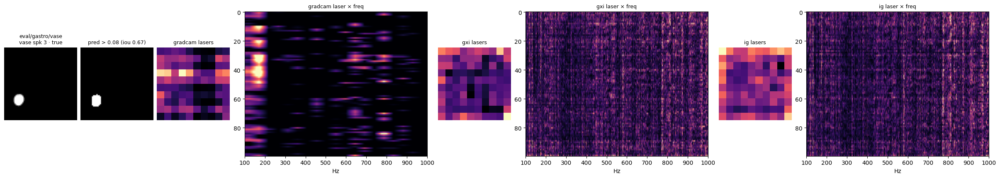

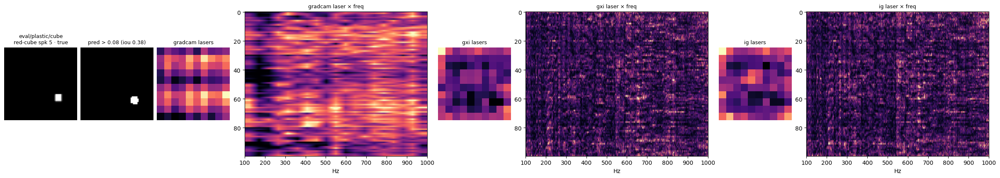

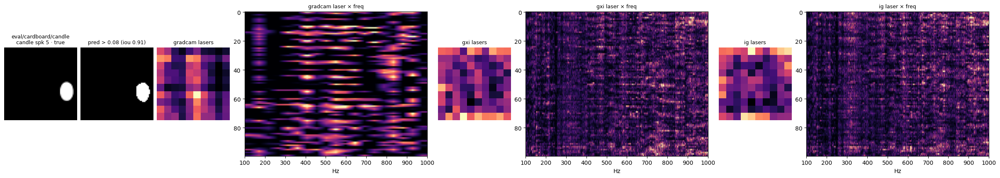

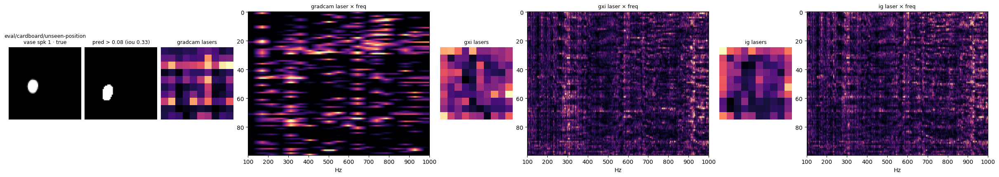

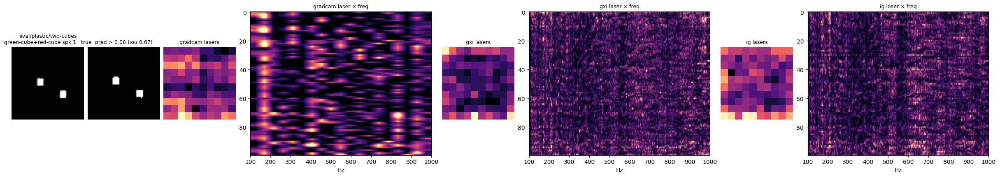

In [32]:
from PIL import Image
want = ["eval/gastro/vase", "eval/plastic/cube", "eval/cardboard/candle", "eval/cardboard/unseen-position", "eval/plastic/two-cubes"]
for sp in [w for w in want if w in EX]:
    i, maps, m = EX[sp]
    fig = plt.figure(figsize=(24, 4.2), constrained_layout=True); gs = fig.add_gridspec(1, 2 + 2 * len(METHODS), width_ratios=[1, 1] + [1, 2.5] * len(METHODS))
    a = fig.add_subplot(gs[0]); a.imshow(Y[i], cmap="gray"); a.set_title(f"{sp}\n{df.object.iloc[i]} spk {df.speaker.iloc[i]} · true", fontsize=9); a.axis("off")
    a = fig.add_subplot(gs[1]); a.imshow(m, cmap="gray"); a.set_title(f"pred > {THR} (iou {df[METRIC].iloc[i]:.2f})", fontsize=9); a.axis("off")
    for n, k in enumerate(METHODS):
        a = fig.add_subplot(gs[2 + 2 * n]); a.imshow(maps[k].sum(1).reshape(R, Cc), cmap="magma"); a.set_title(f"{k} lasers", fontsize=9); a.axis("off")
        a = fig.add_subplot(gs[3 + 2 * n]); a.imshow(maps[k], aspect="auto", cmap="magma", vmax=np.percentile(maps[k], 99.5), extent=[FREQS[0], FREQS[-1], L - 0.5, -0.5])
        a.set_title(f"{k} laser × freq", fontsize=9); a.set_xlabel("Hz")
    plt.show()

In [33]:
IMP_GRAD = {f"laser_{k}": LAS[k] for k in LM} | {f"freq_{k}": band(MAP[k].sum(0)) for k in METHODS}

**Findings (2066/2142 eval samples).** Every map is close to flat: the top laser holds ~1.6-1.8 % against 1 % uniform, and the top band is ×1.3. Nothing dominates, the same as nb104's occlusion result.
- **Grad-CAM** (band tokens, last freq block): laser row 6 stands out, (6,6) peaks, and the low bands 100-200 Hz are strongest, then 300-400 Hz. Per sample it is sparse, a few (laser, band) blobs.
- **HiResCAM** (laser stage, 10×10): border/corner lasers, (9,1), (9,9), (9,0), (0,0) ~1.5 %; agrees with grad×input / IG (Spearman 0.79 / 0.76), not with the freq-stage Grad-CAM (−0.23). It uses no input scaling, so the border preference is not only an |x| effect. The one outlier is the library's band-level Grad-CAM (global channel weights + per-sample min-max).
- **grad×input / IG** agree (laser Spearman 0.93) but disagree with Grad-CAM (≈ −0.2). They favour the grid's border lasers (corners (0,0), (9,9), (9,0), (0,9)) and the top of the sweep, 890-1000 Hz. Both scale by the normalized input |x|, so they also weight where the input deviates most from the train mean. The border and band-edge bins may just be noisier (nb95/nb100), so read them as "input × sensitivity", not as pure sensitivity.

## 3 · Do the methods agree?
Every method as one importance per laser (100) and per band (19), higher = more important; Spearman ρ between methods. Token masking and
occlusion are Δ`METRIC` (sign flipped so that "removing it hurts" is positive); attention = the CLS analogs (readout share / rollout for lasers,
`pool_q` attention / rollout for bands); gradient maps = the eval-mean share (per-bin maps summed into the model's 64-bin bands).

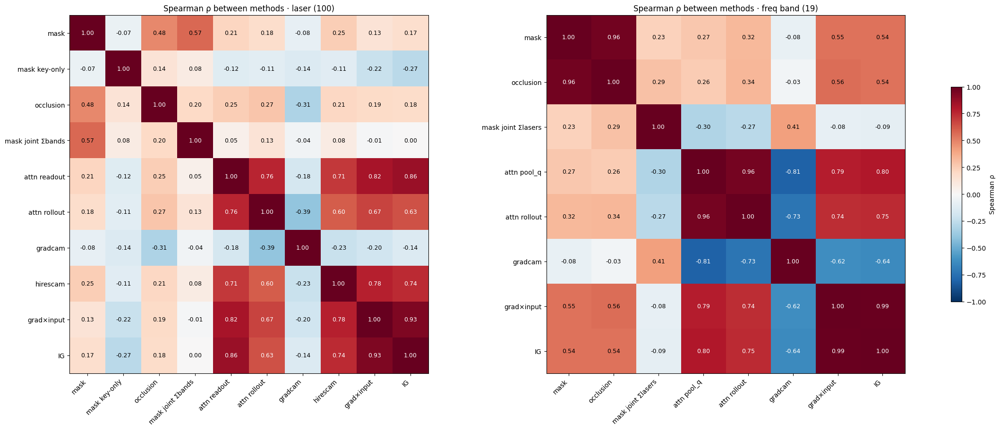

laser (100)
                   mask  mask key-only  occlusion  mask joint Σbands  attn readout  attn rollout  gradcam  hirescam  grad×input    IG
mask               1.00          -0.07       0.48               0.57          0.21          0.18    -0.08      0.25        0.13  0.17
mask key-only     -0.07           1.00       0.14               0.08         -0.12         -0.11    -0.14     -0.11       -0.22 -0.27
occlusion          0.48           0.14       1.00               0.20          0.25          0.27    -0.31      0.21        0.19  0.18
mask joint Σbands  0.57           0.08       0.20               1.00          0.05          0.13    -0.04      0.08       -0.01  0.00
attn readout       0.21          -0.12       0.25               0.05          1.00          0.76    -0.18      0.71        0.82  0.86
attn rollout       0.18          -0.11       0.27               0.13          0.76          1.00    -0.39      0.60        0.67  0.63
gradcam           -0.08          -0.14      -0.31 

In [34]:
LASER_IMP = {"mask": IMP_MASK["laser"], "mask key-only": IMP_MASK["laser_keyonly"], "occlusion": IMP_MASK["laser_occ"], "mask joint Σbands": IMP_MASK["joint"].sum(1),
             "attn readout": IMP_ATTN["laser_readout"], "attn rollout": IMP_ATTN["laser_rollout"],
             "gradcam": IMP_GRAD["laser_gradcam"], "hirescam": IMP_GRAD["laser_hirescam"], "grad×input": IMP_GRAD["laser_gxi"], "IG": IMP_GRAD["laser_ig"]}
FREQ_IMP = {"mask": IMP_MASK["freq"], "occlusion": IMP_MASK["freq_occ"], "mask joint Σlasers": IMP_MASK["joint"].sum(0),
            "attn pool_q": IMP_ATTN["freq_pool"], "attn rollout": IMP_ATTN["freq_rollout"],
            "gradcam": IMP_GRAD["freq_gradcam"], "grad×input": IMP_GRAD["freq_gxi"], "IG": IMP_GRAD["freq_ig"]}
RHO = {k: pd.DataFrame(v).corr("spearman") for k, v in [("laser (100)", LASER_IMP), ("freq band (19)", FREQ_IMP)]}
fig, axs = plt.subplots(1, 2, figsize=(22, 9), constrained_layout=True)
for ax, (name, r) in zip(axs, RHO.items()):
    im = ax.imshow(r.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(r)), r.columns, rotation=45, ha="right"); ax.set_yticks(range(len(r)), r.index)
    for i in range(len(r)):
        for j in range(len(r)): ax.text(j, i, f"{r.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(r.values[i, j]) > 0.6 else "black")
    ax.set_title(f"Spearman ρ between methods · {name}")
fig.colorbar(im, ax=axs, shrink=0.6, label="Spearman ρ")
plt.show()
for k, r in RHO.items(): print(k); print(r.round(2).to_string())
# chance level: |ρ| > ~0.20 (lasers, n=100) or ~0.46 (bands, n=19) is p < .05

In [35]:
# top 5 per method
hz = lambda b: f"{BAND_LO[b]:.0f}-{BAND_HI[b]:.0f}"
display(pd.DataFrame({k: [f"({l // Cc},{l % Cc})" for l in np.argsort(-v)[:5]] for k, v in LASER_IMP.items()}, index=[f"#{i + 1}" for i in range(5)]).T.rename_axis("top lasers (row,col)"))
display(pd.DataFrame({k: [hz(b) for b in np.argsort(-v)[:5]] for k, v in FREQ_IMP.items()}, index=[f"#{i + 1}" for i in range(5)]).T.rename_axis("top bands (Hz)"))

,#1,#2,#3,#4,#5
"top lasers (row,col)",,,,,
mask,"(5,1)","(0,2)","(0,5)","(0,9)","(7,5)"
mask key-only,"(7,2)","(2,4)","(3,2)","(7,3)","(8,7)"
occlusion,"(9,9)","(4,0)","(9,1)","(8,9)","(0,2)"
mask joint Σbands,"(4,1)","(9,9)","(2,4)","(9,6)","(7,9)"
attn readout,"(0,0)","(9,0)","(0,9)","(9,9)","(0,4)"
attn rollout,"(0,0)","(9,1)","(9,9)","(9,0)","(0,9)"
gradcam,"(6,6)","(6,9)","(6,8)","(6,7)","(1,6)"
hirescam,"(9,1)","(9,9)","(9,0)","(0,4)","(0,0)"
grad×input,"(0,0)","(9,9)","(9,0)","(9,3)","(0,9)"


,#1,#2,#3,#4,#5
top bands (Hz),,,,,
mask,938-986,888-937,642-691,199-247,839-888
occlusion,938-986,888-937,642-691,199-247,149-198
mask joint Σlasers,100-149,543-592,888-937,741-789,149-198
attn pool_q,790-838,938-986,839-888,987-1000,888-937
attn rollout,790-838,938-986,839-888,888-937,691-740
gradcam,100-149,149-198,346-395,297-346,199-247
grad×input,987-1000,888-937,938-986,642-691,741-789
IG,987-1000,888-937,938-986,642-691,741-789


## Summary (s9-transformer-vase-1k ep1000, 3142 samples: 1000 train + 2142 eval, `IGNORE` = cardboard vase-laser-shifted-4)
**Architecture facts.**
- **Input after normalization**: `Encoder.normalize` = `(x - cum_mean[box]) * cum_std[box]`, per box and per (laser, bin, axis), using the train stats stored in the checkpoint. It is captured as the input to `encoder.freq_enc`.
- **Latent**: the encoder output (1024-d) that the decoder and every aux head read.
- **Penultimate**: the input to `decoder.conv3` (32×64×64).
- **No CLS token**: the 100 laser tokens are read by LayerNorm → flatten → Linear. The only learned query is the band pool `pool_q`, which runs per laser and over freq only.
- **Speckles** = connected components (4-conn) of the predicted mask at p > 0.08. Of 3142 predictions, 2707 have 1 blob, 334 have 2, 11 have 3 and 90 are empty, so the model does not produce speckle.

**Embeddings** (t-SNE, 10-NN label agreement):
- **Input**: organized by speaker (.99, chance .24) and box (1.00), with no position.
- **Latent**: box (1.00) and speaker (.75) are still there; x becomes readable (R² .55 from the 3 coords).
- **Penultimate**: speaker drops to chance (.24) and position is readable (x .69, y .74). This is the first representation that describes the scene rather than the recording.
- **Train vs eval**: they sit together in every panel.

**Importance.**
- **Freq bands matter; single lasers barely do.**
  - **Bands**: removing one ~49 Hz band (in every laser) costs up to .027 iou@0.08. The top bands are 938-986, 888-937, 642-691 and 199-247 Hz.
  - **Lasers**: removing one laser costs at most .0018. Lasers are redundant, consistent with nb104/nb106.
  - **Per box**: cardboard reads the high bands (.045 at 938-986 Hz); plastic reads 199-296 Hz. This matches nb106.
- **Masking and occlusion agree** on bands (ρ .96) and moderately on lasers (.48).
- **Key-padding a laser alone does nothing** (Δ ≈ 0, ρ ≈ 0 with everything): the laser's own residual stream still reaches the flatten readout. A laser is only really removed when its readout slot is cut as well.
- **The joint (laser, band) map is noise.** Each token is worth ≤ .0009, and the rank-1 share is .12.
- **Attention is near uniform**: max ≈ 2× uniform, and the mean attended distance equals the uniform one. The CLS analogs (laser readout share, `pool_q`) mostly say "border lasers" and "high bands".
- **grad×input / IG** agree with each other (.93/.99) and with the attention readout share (lasers ρ .82-.86). They pick the corner and border lasers and the top of the sweep, i.e. they track token norm × sensitivity. Against masking they reach only ρ .13-.25 on lasers and .55 on bands.
- **Grad-CAM** (last freq block) is the outlier. It favours laser row 6 and 100-200 Hz, and it anti-correlates with the other freq rankings (ρ -.6 to -.8). Its gradient-pooled weights on band tokens do not measure what removing a band does.
- **Bottom line**: use **token masking / occlusion** as the importance. Attention and gradient maps here mostly reflect input magnitude and the readout layout.